# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  879M    0  879M    0     0  3432k      0 --:--:--  0:04:22 --:--:-- 7262k


In [2]:
!rm SUSY.csv

In [3]:
!gunzip SUSY.csv.gz

In [4]:
ls -lh

total 4697752
-rw-r--r--  1 zainabfiyyaz  staff   149K Nov  6 20:21 Lab.7.pdf
-rw-r--r--  1 zainabfiyyaz  staff   357K Nov 25 23:25 Lab.7.recovered.ipynb
-rw-r--r--  1 zainabfiyyaz  staff   2.2G Nov 25 23:27 SUSY.csv


The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

total 4697752
-rw-r--r--  1 zainabfiyyaz  staff   149K Nov  6 20:21 Lab.7.pdf
-rw-r--r--  1 zainabfiyyaz  staff   357K Nov 25 23:25 Lab.7.recovered.ipynb
-rw-r--r--  1 zainabfiyyaz  staff   2.2G Nov 25 23:27 SUSY.csv


We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

total 5164608
-rw-r--r--  1 zainabfiyyaz  staff   149K Nov  6 20:21 Lab.7.pdf
-rw-r--r--@ 1 zainabfiyyaz  staff   358K Nov 25 23:29 Lab.7.recovered.ipynb
-rw-r--r--  1 zainabfiyyaz  staff   228M Nov 25 23:29 SUSY-small.csv
-rw-r--r--  1 zainabfiyyaz  staff   2.2G Nov 25 23:27 SUSY.csv


In [10]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [11]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [13]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['cos_theta_r1',
 'M_R',
 'R',
 'S_R',
 'axial_MET',
 'MET_rel',
 'M_Delta_R',
 'dPhi_r_b',
 'M_TR_2',
 'MT2']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [16]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [17]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [18]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


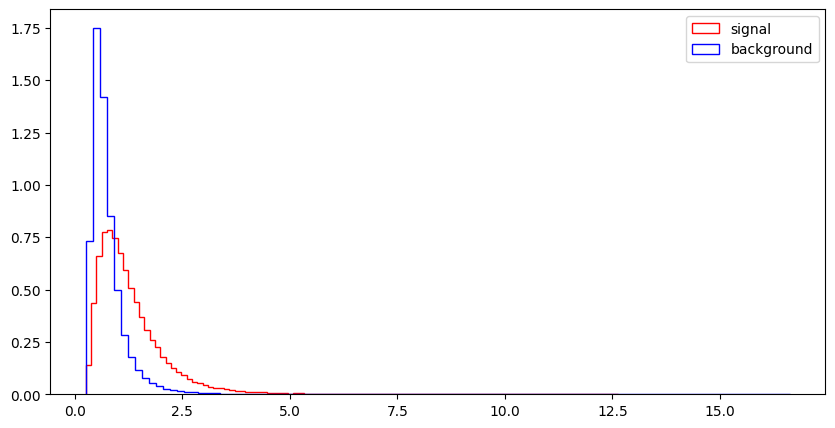

l_1_eta


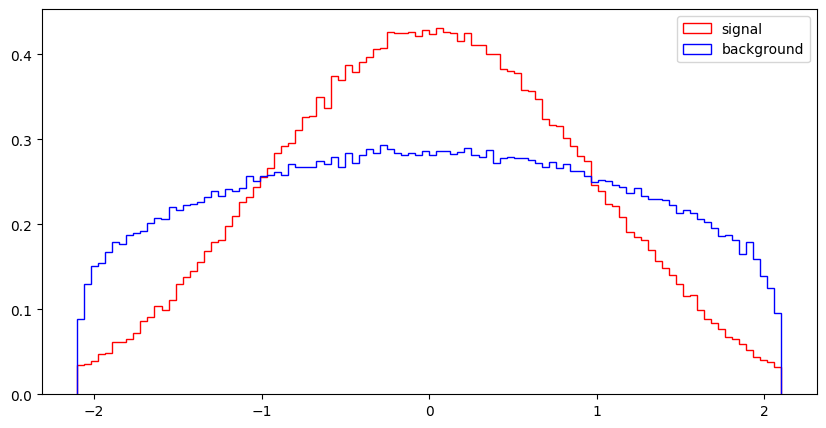

l_1_phi


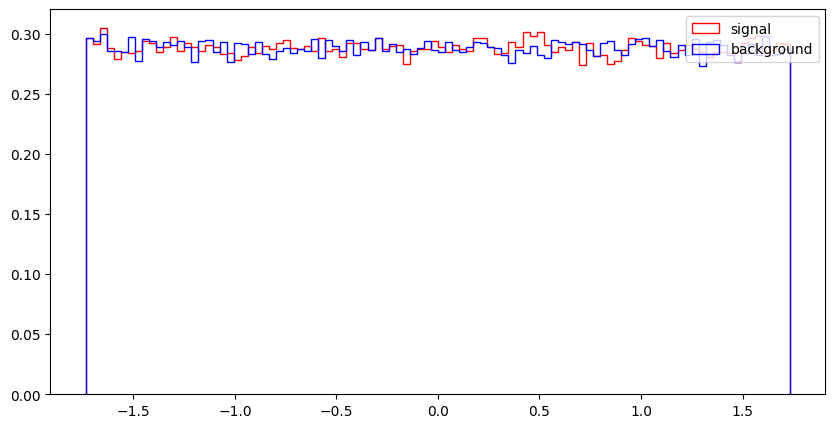

l_2_pT


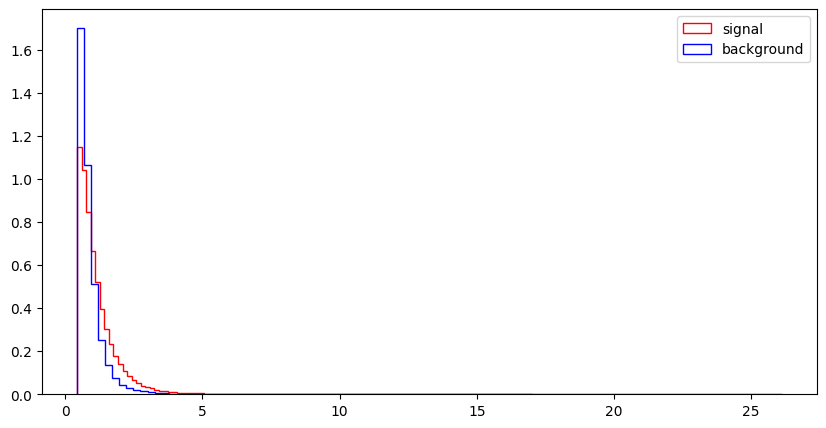

l_2_eta


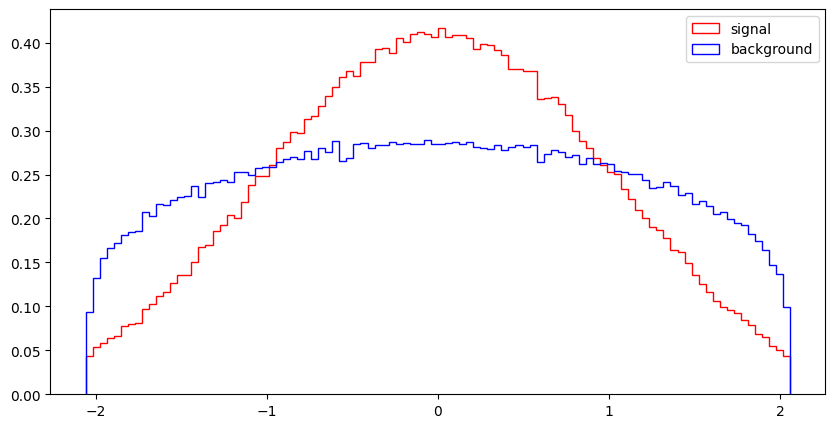

l_2_phi


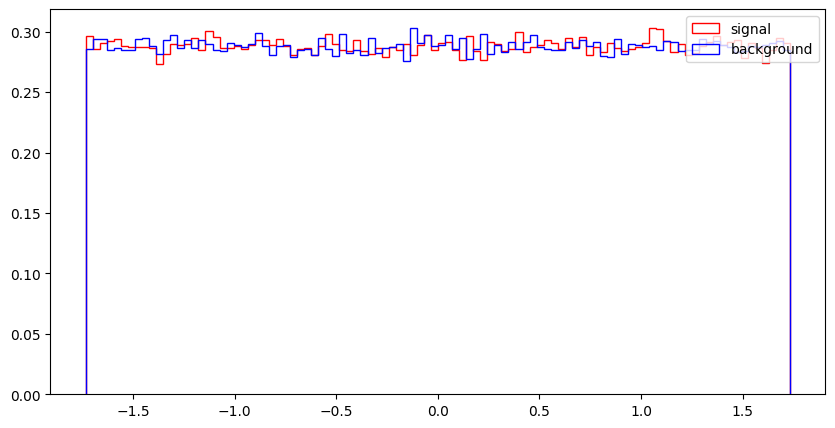

MET


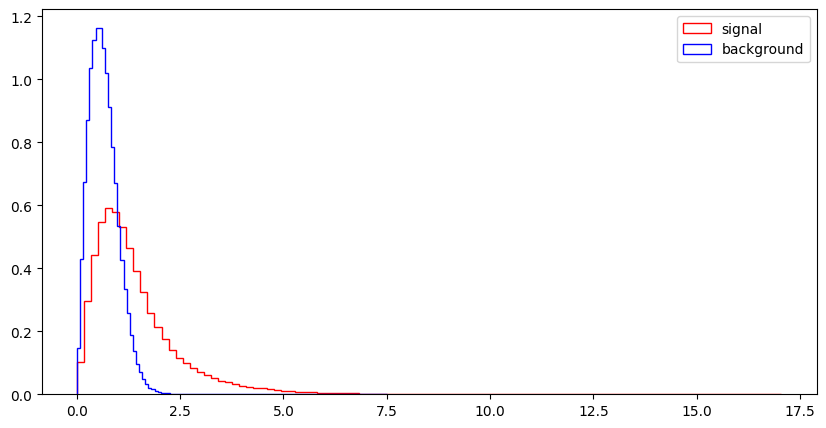

MET_phi


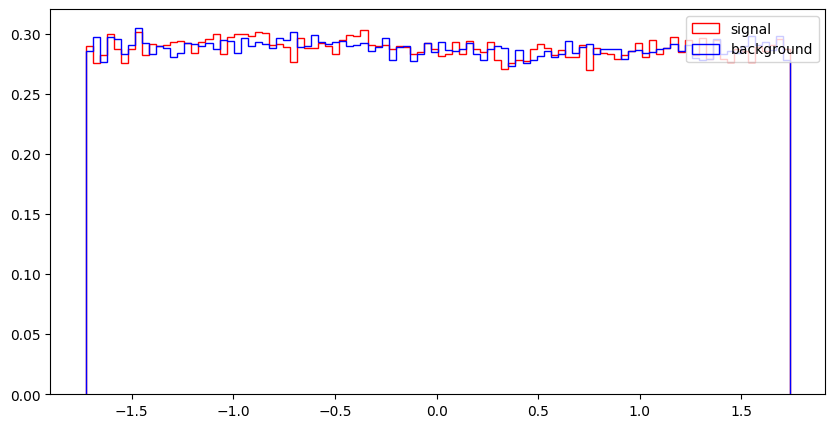

MET_rel


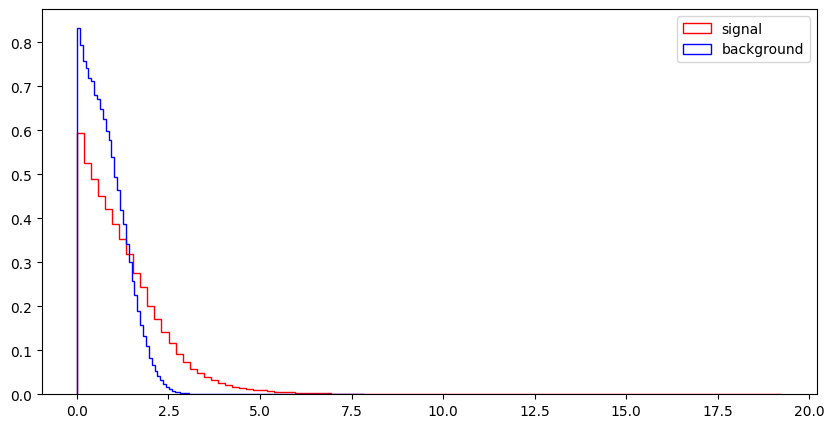

axial_MET


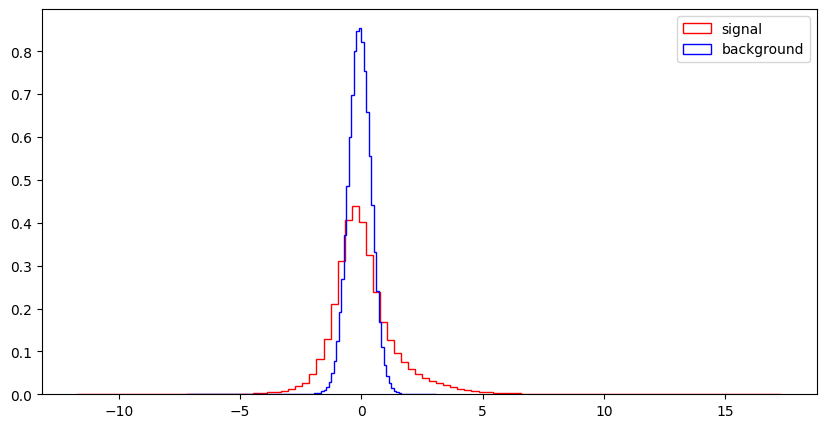

M_R


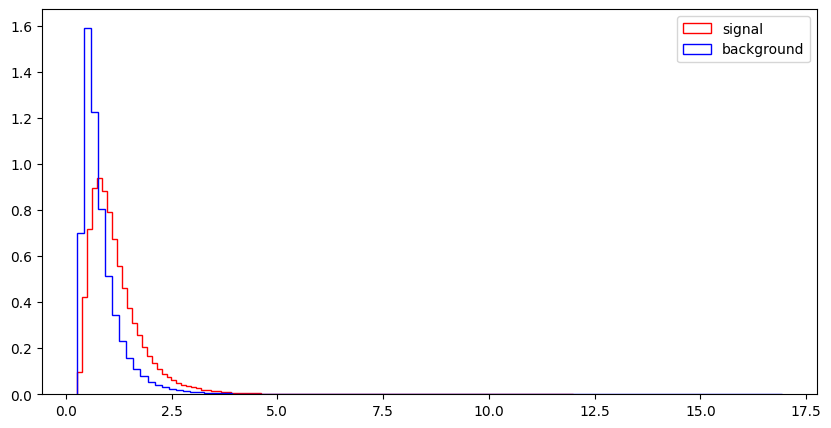

M_TR_2


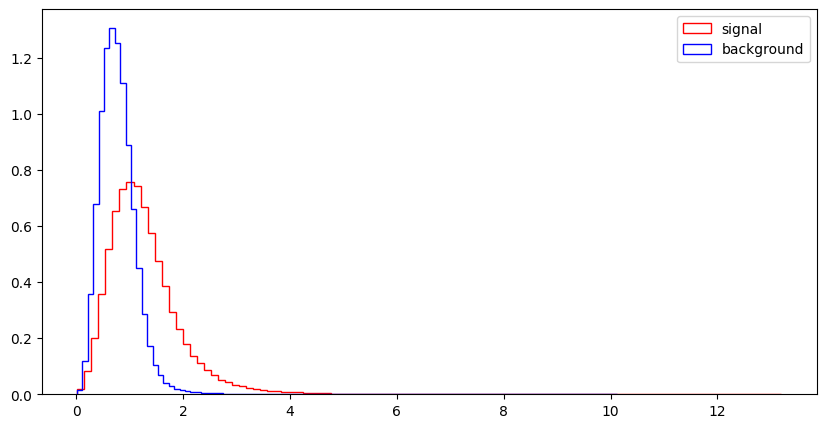

R


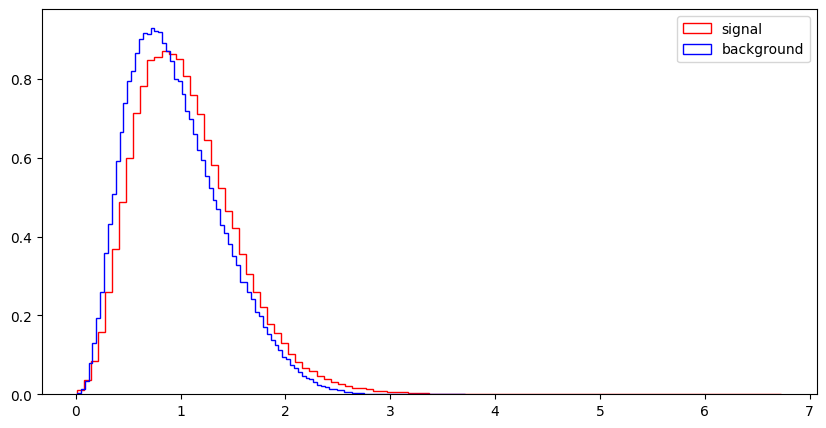

MT2


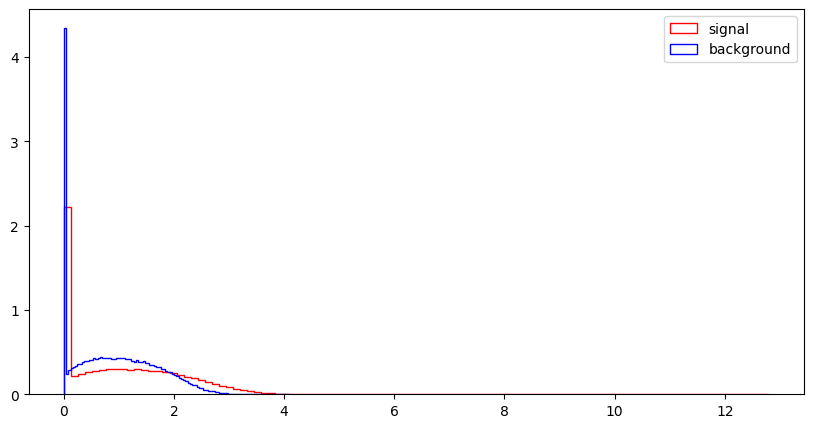

S_R


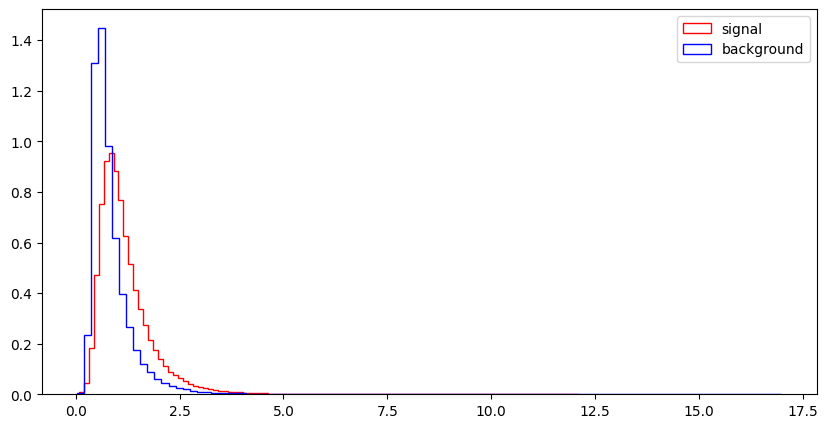

M_Delta_R


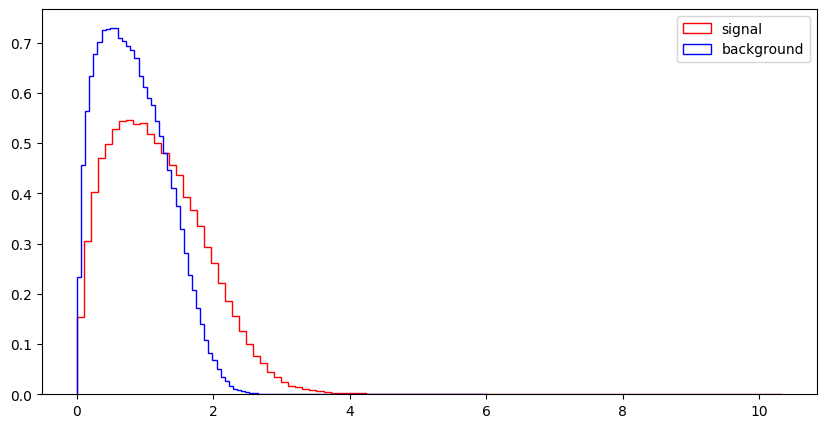

dPhi_r_b


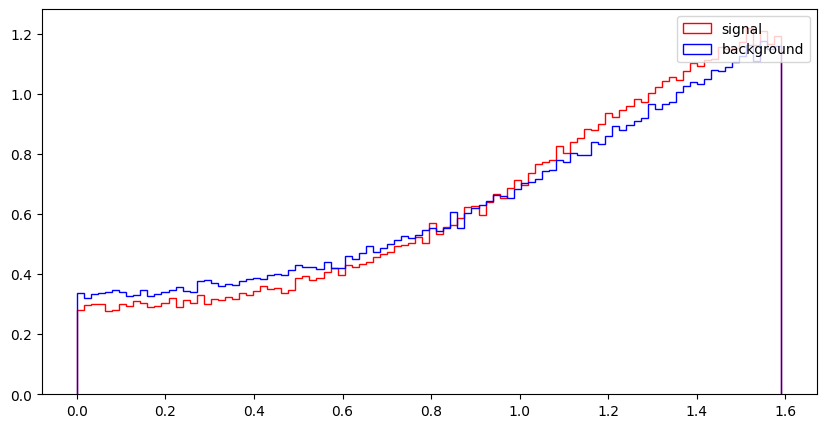

cos_theta_r1


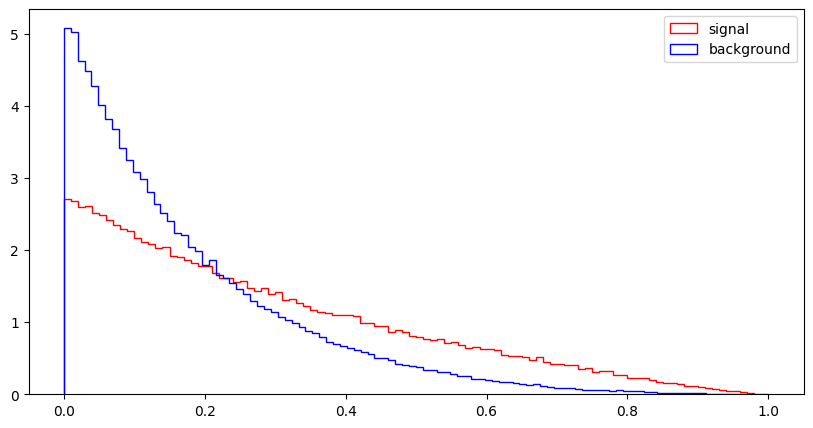

In [19]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Physics-style axis labels for each variable
labels = {
    "l_1_pT": r"Lepton 1 $p_T$", "l_1_eta": r"Lepton 1 $\eta$", "l_1_phi": r"Lepton 1 $\phi$",
    "l_2_pT": r"Lepton 2 $p_T$", "l_2_eta": r"Lepton 2 $\eta$", "l_2_phi": r"Lepton 2 $\phi$",
    "MET": r"Missing $E_T$", "MET_phi": r"Missing $E_T$ $\phi$",
    "MET_rel": r"$E_T^{miss,rel}$", "axial_MET": r"Axial $E_T^{miss}$",
    "M_R": r"$M_R$", "M_TR_2": r"$M_{TR}^{2}$", "R": r"$R$", "MT2": r"$M_{T2}$",
    "S_R": r"$\sqrt{\hat{s}_R}$", "M_Delta_R": r"$M_{\Delta}^{R}$",
    "dPhi_r_b": r"$\Delta\phi_R^\beta$", "cos_theta_r1": r"$\cos(\theta_{R+1})$",
}

def plot_grid(var_list, nrows, ncols, title):
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.5 * nrows))
    axes = axes.flatten()
    for ax, var in zip(axes, var_list):
        # trim extreme tails so the main shape is visible
        lo, hi = np.percentile(df[var], [0.5, 99.5])
        bins = np.linspace(lo, hi, 50)
        sig = df_sig[var].to_numpy()
        bkg = df_bkg[var].to_numpy()
        # weights make each histogram sum to 1 -> true "fraction of events"
        ax.hist(sig, bins=bins, histtype="step", color="black", linewidth=1.5,
                weights=np.ones(len(sig)) / len(sig), label="Signal")
        ax.hist(bkg, bins=bins, histtype="step", color="red", linewidth=1.5,
                weights=np.ones(len(bkg)) / len(bkg), label="Background")
        ax.set_xlabel(labels[var], fontsize=12)
        ax.set_ylabel("Fraction of events", fontsize=11)
        ax.legend(fontsize=9, frameon=False)
    for ax in axes[len(var_list):]:   # hide any unused panels
        ax.set_visible(False)
    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    plt.show()

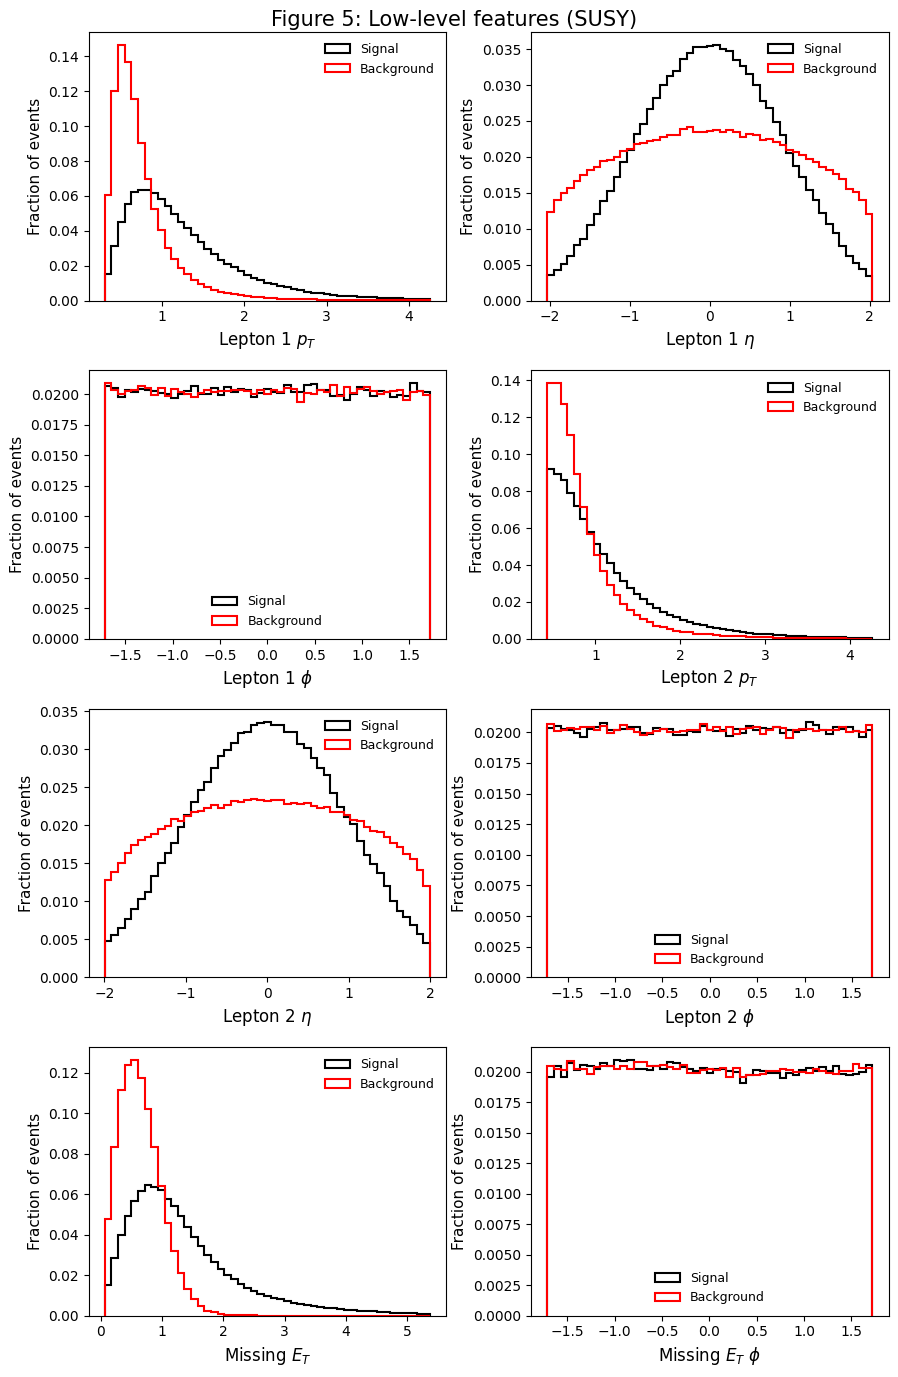

In [21]:
plot_grid(RawNames, 4, 2, "Figure 5: Low-level features (SUSY)")

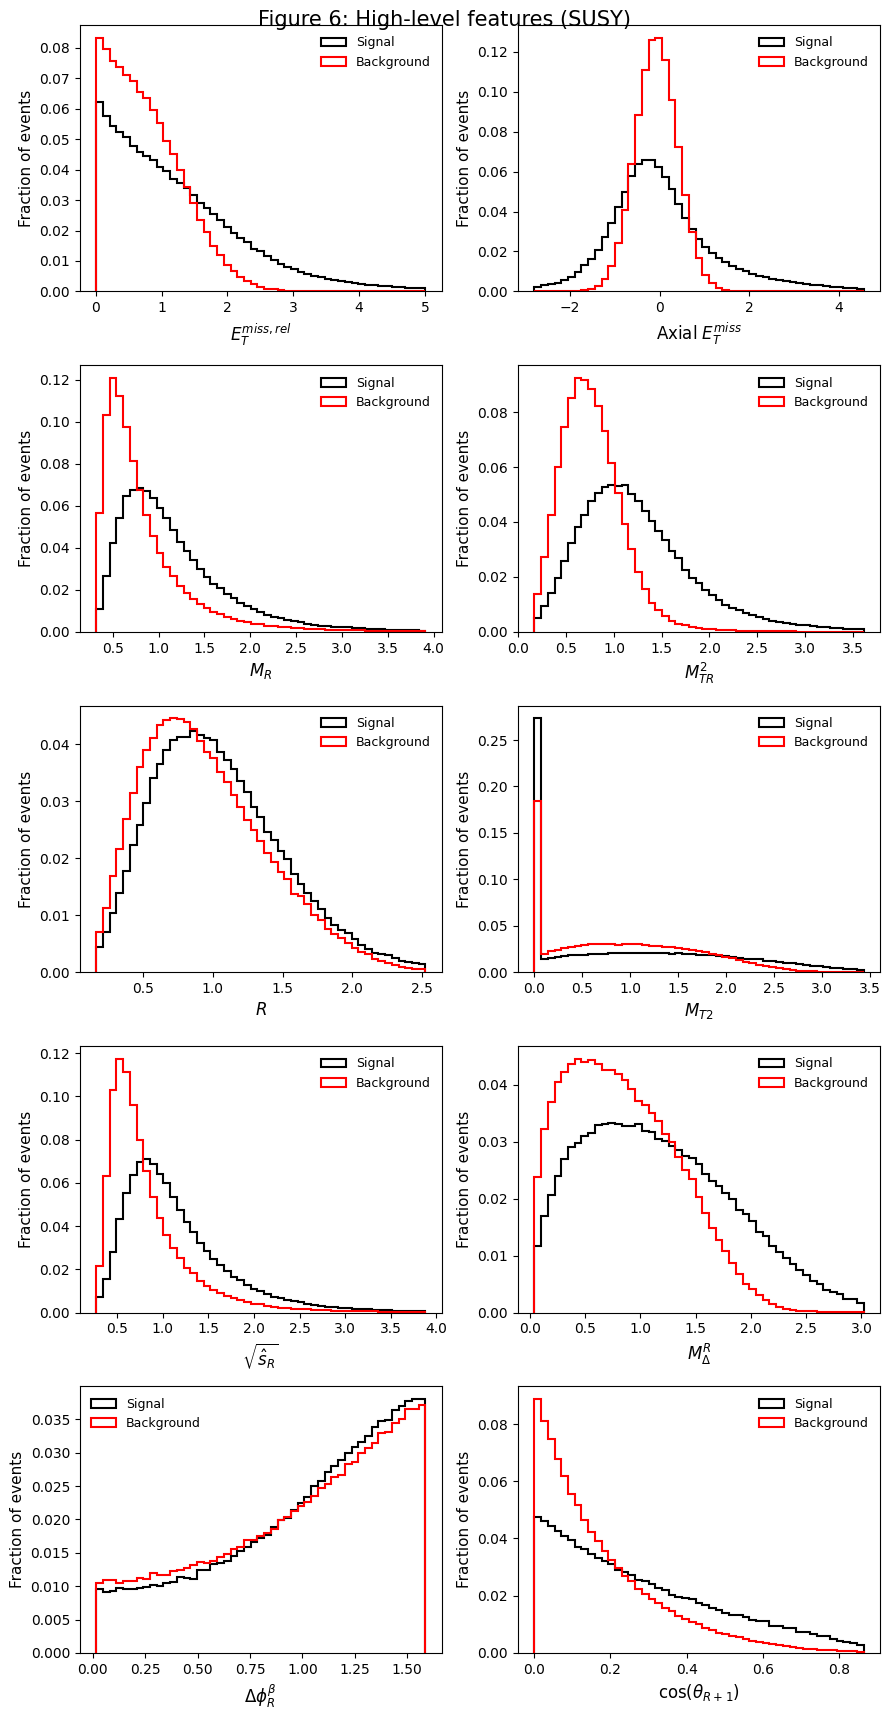

In [22]:
HighLevel = VarNames[9:]   # keeps a fixed order (FeatureNames is shuffled because it came from a set)
plot_grid(HighLevel, 5, 2, "Figure 6: High-level features (SUSY)")

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

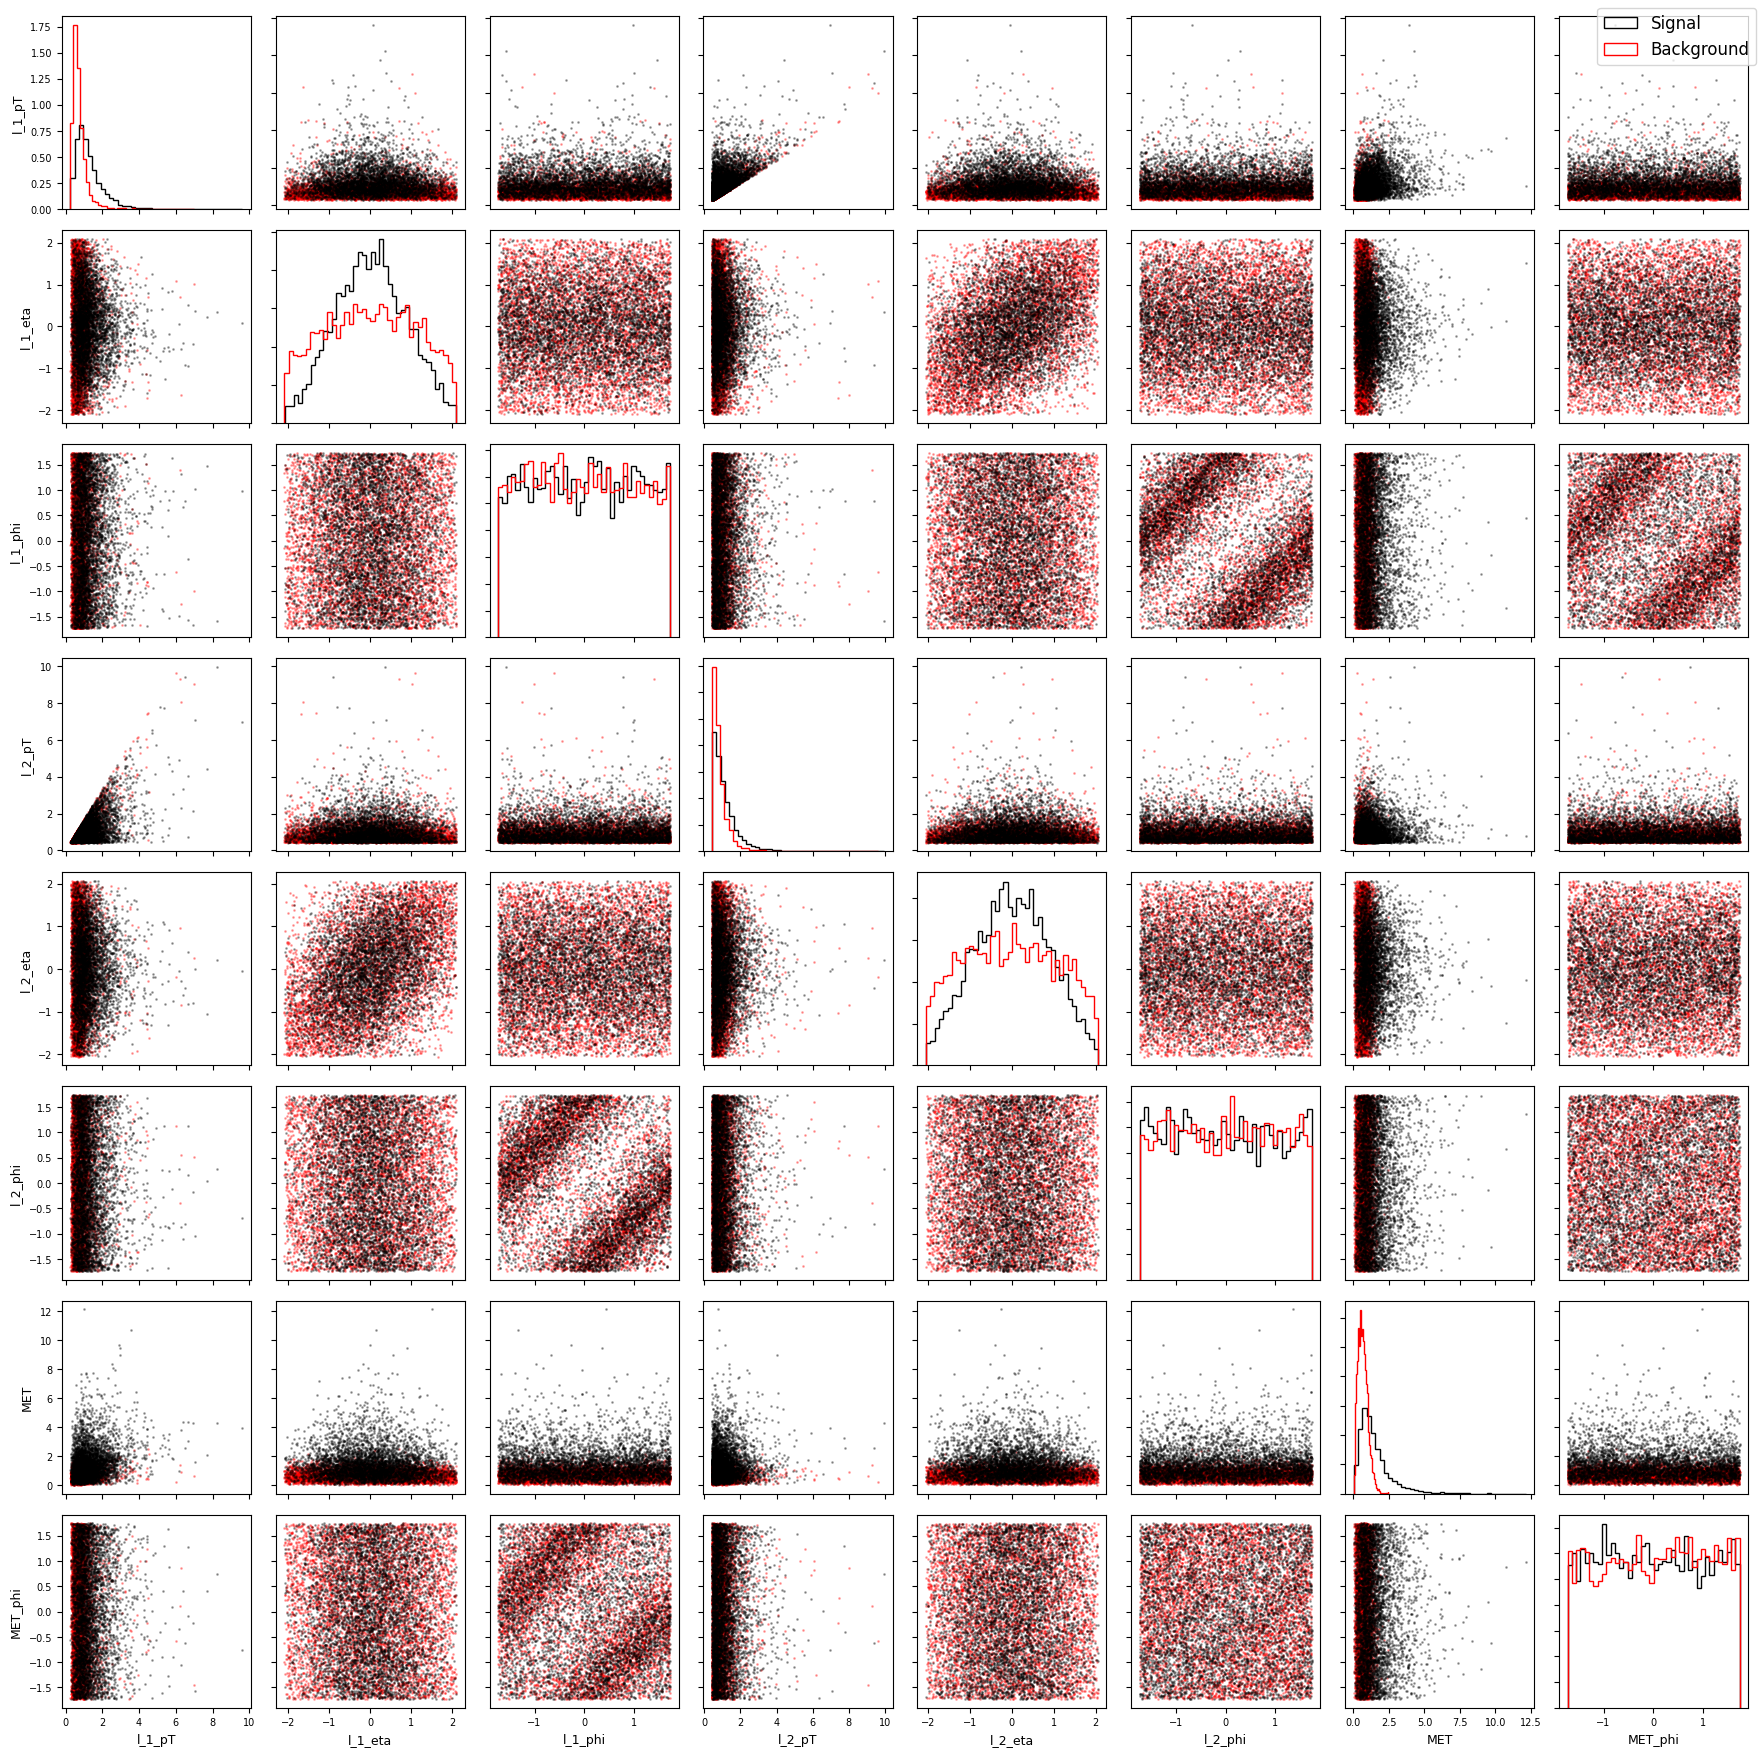

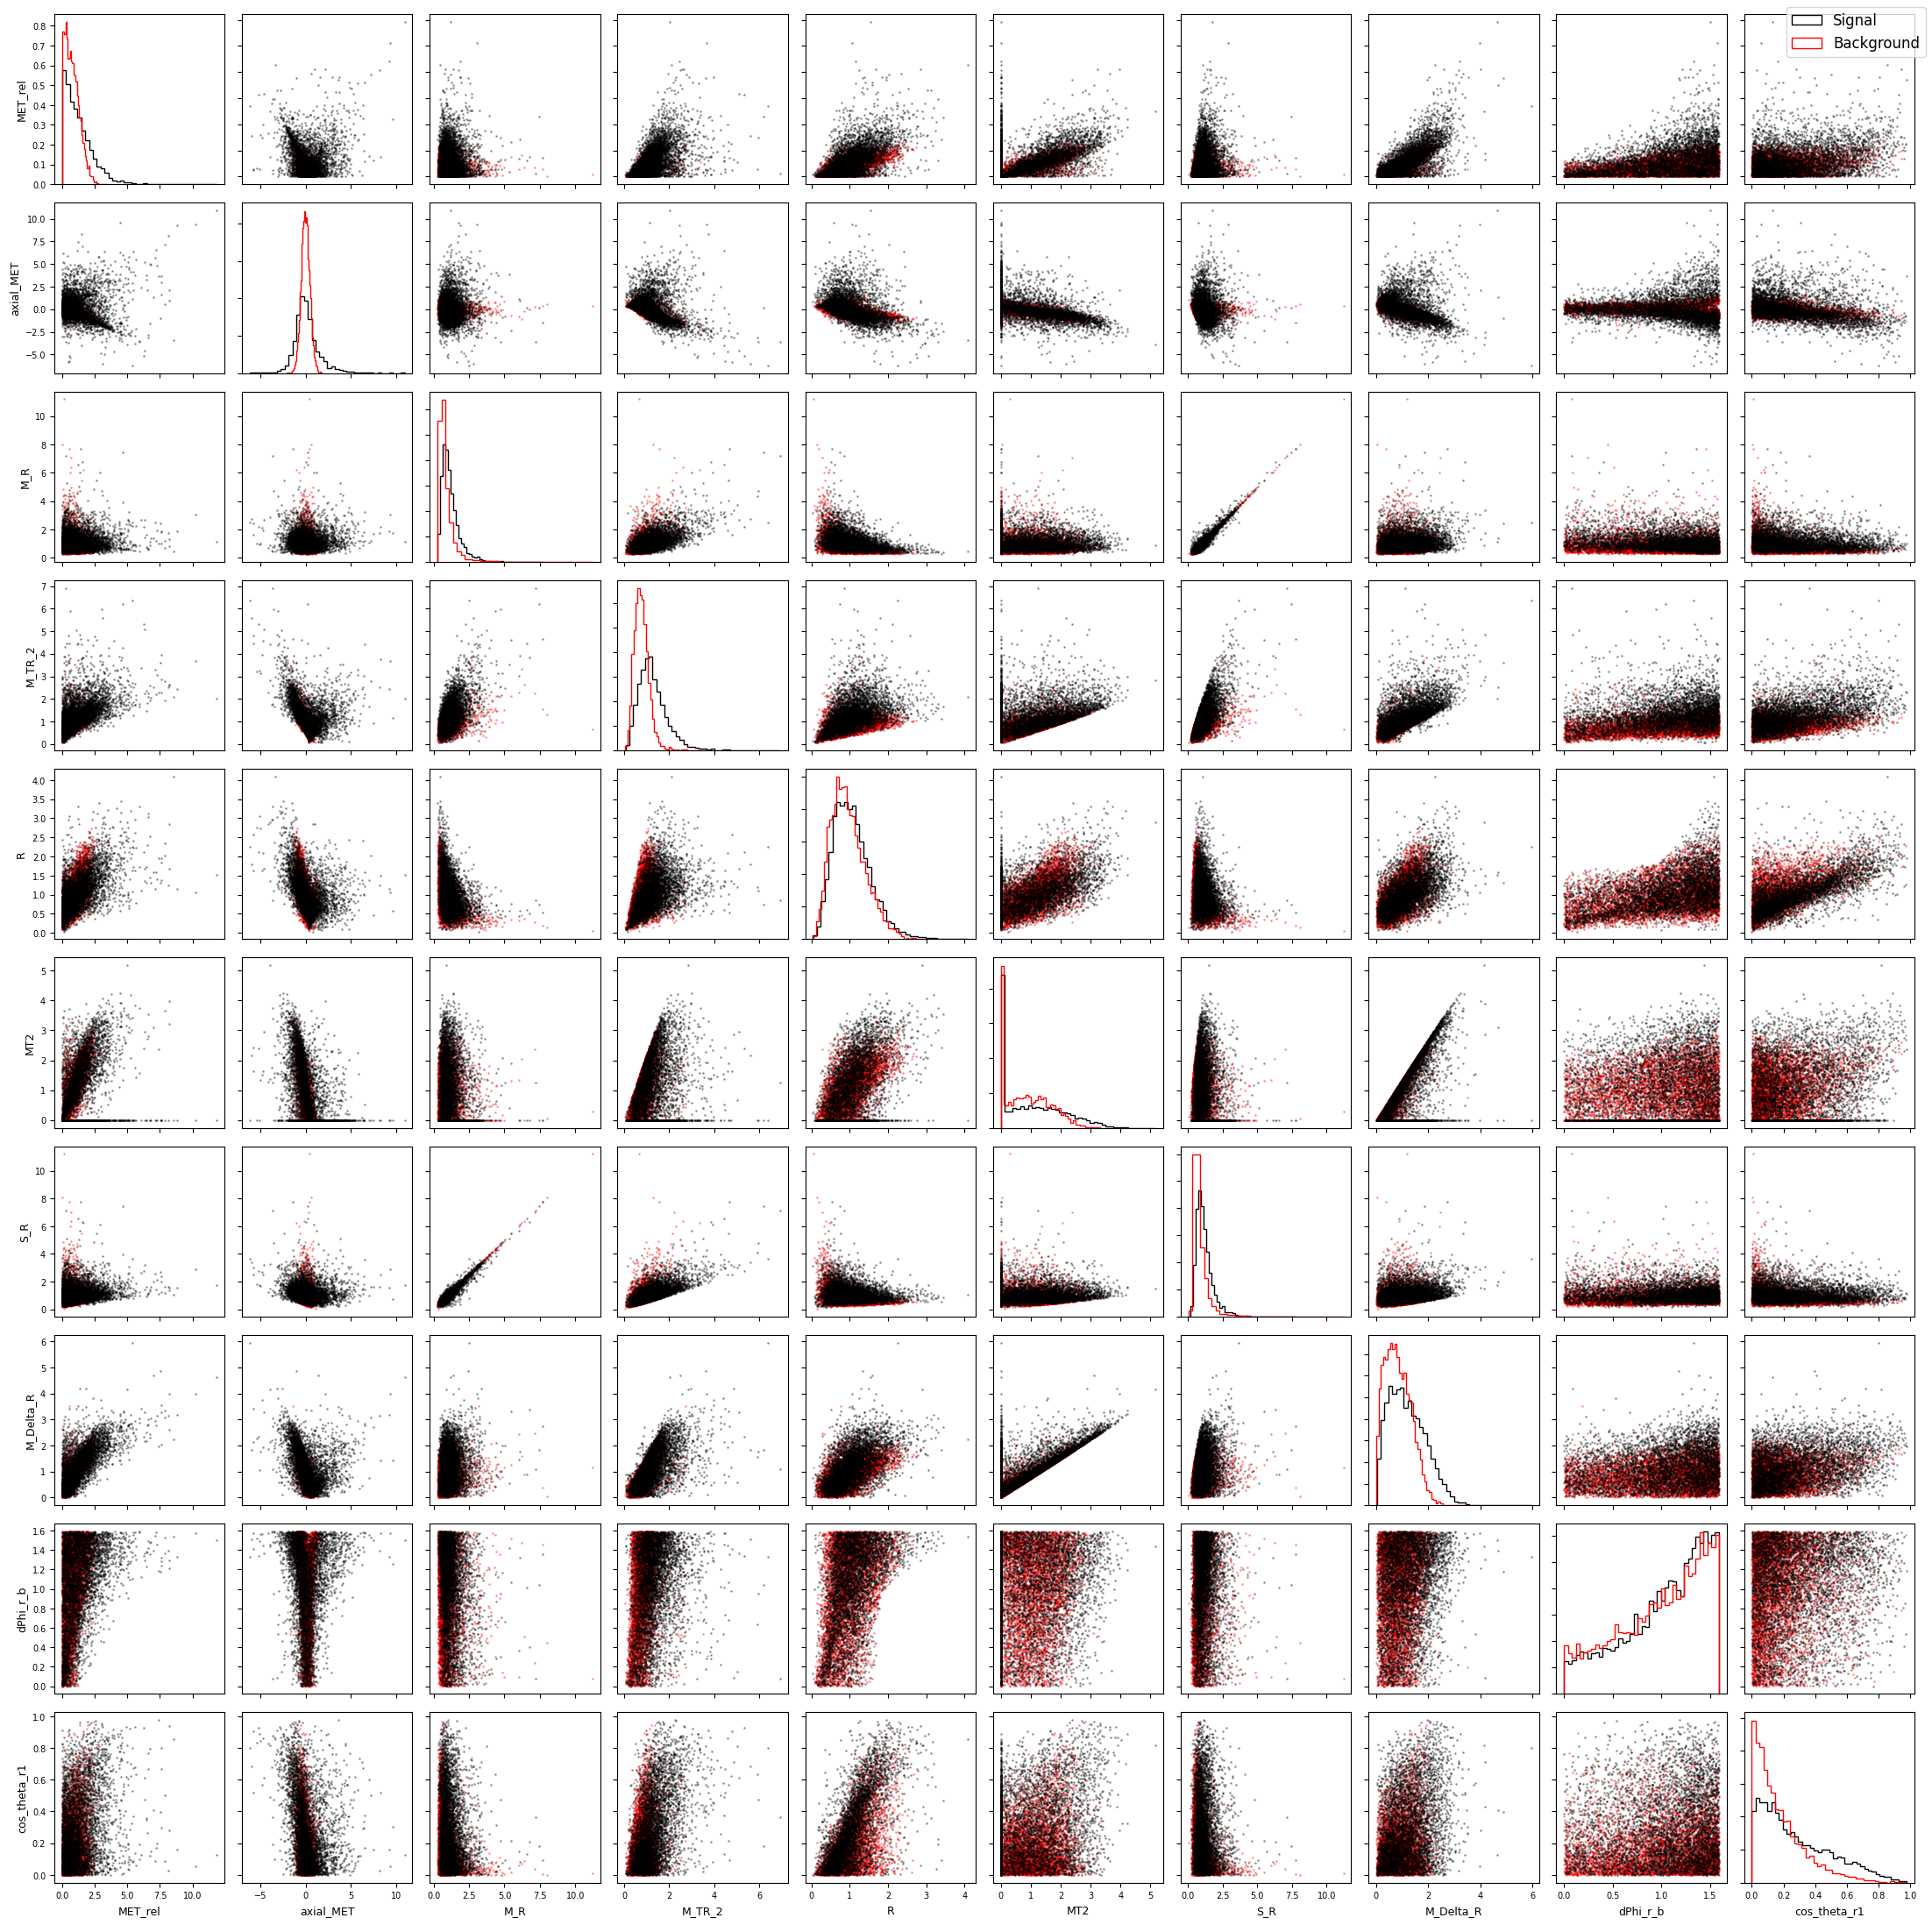

In [23]:
import numpy as np
import matplotlib.pyplot as plt

def pair_plot(sig, bkg, var_list, bins=40):
    n = len(var_list)
    fig, axes = plt.subplots(n, n, figsize=(2.2 * n, 2.2 * n))
    for i, y_var in enumerate(var_list):
        for j, x_var in enumerate(var_list):
            ax = axes[i, j]
            if i == j:
                # diagonal: 1D histogram of that variable
                ax.hist(sig[x_var], bins=bins, histtype="step", color="black", density=True)
                ax.hist(bkg[x_var], bins=bins, histtype="step", color="red", density=True)
            else:
                # off-diagonal: scatter of one variable against another
                ax.scatter(bkg[x_var], bkg[y_var], s=1, color="red", alpha=0.3)
                ax.scatter(sig[x_var], sig[y_var], s=1, color="black", alpha=0.3)
            # only label the outer edge so it stays readable
            if i == n - 1: ax.set_xlabel(x_var, fontsize=9)
            else: ax.set_xticklabels([])
            if j == 0: ax.set_ylabel(y_var, fontsize=9)
            else: ax.set_yticklabels([])
            ax.tick_params(labelsize=7)
    fig.legend(["Signal", "Background"], loc="upper right", fontsize=12)
    plt.tight_layout()
    plt.show()

# a random sample of 5,000 events each keeps the scatter plots from taking forever
sig_sample = df_sig.sample(5000, random_state=0)
bkg_sample = df_bkg.sample(5000, random_state=0)

pair_plot(sig_sample, bkg_sample, RawNames)        # low-level features
pair_plot(sig_sample, bkg_sample, VarNames[9:])    # high-level features

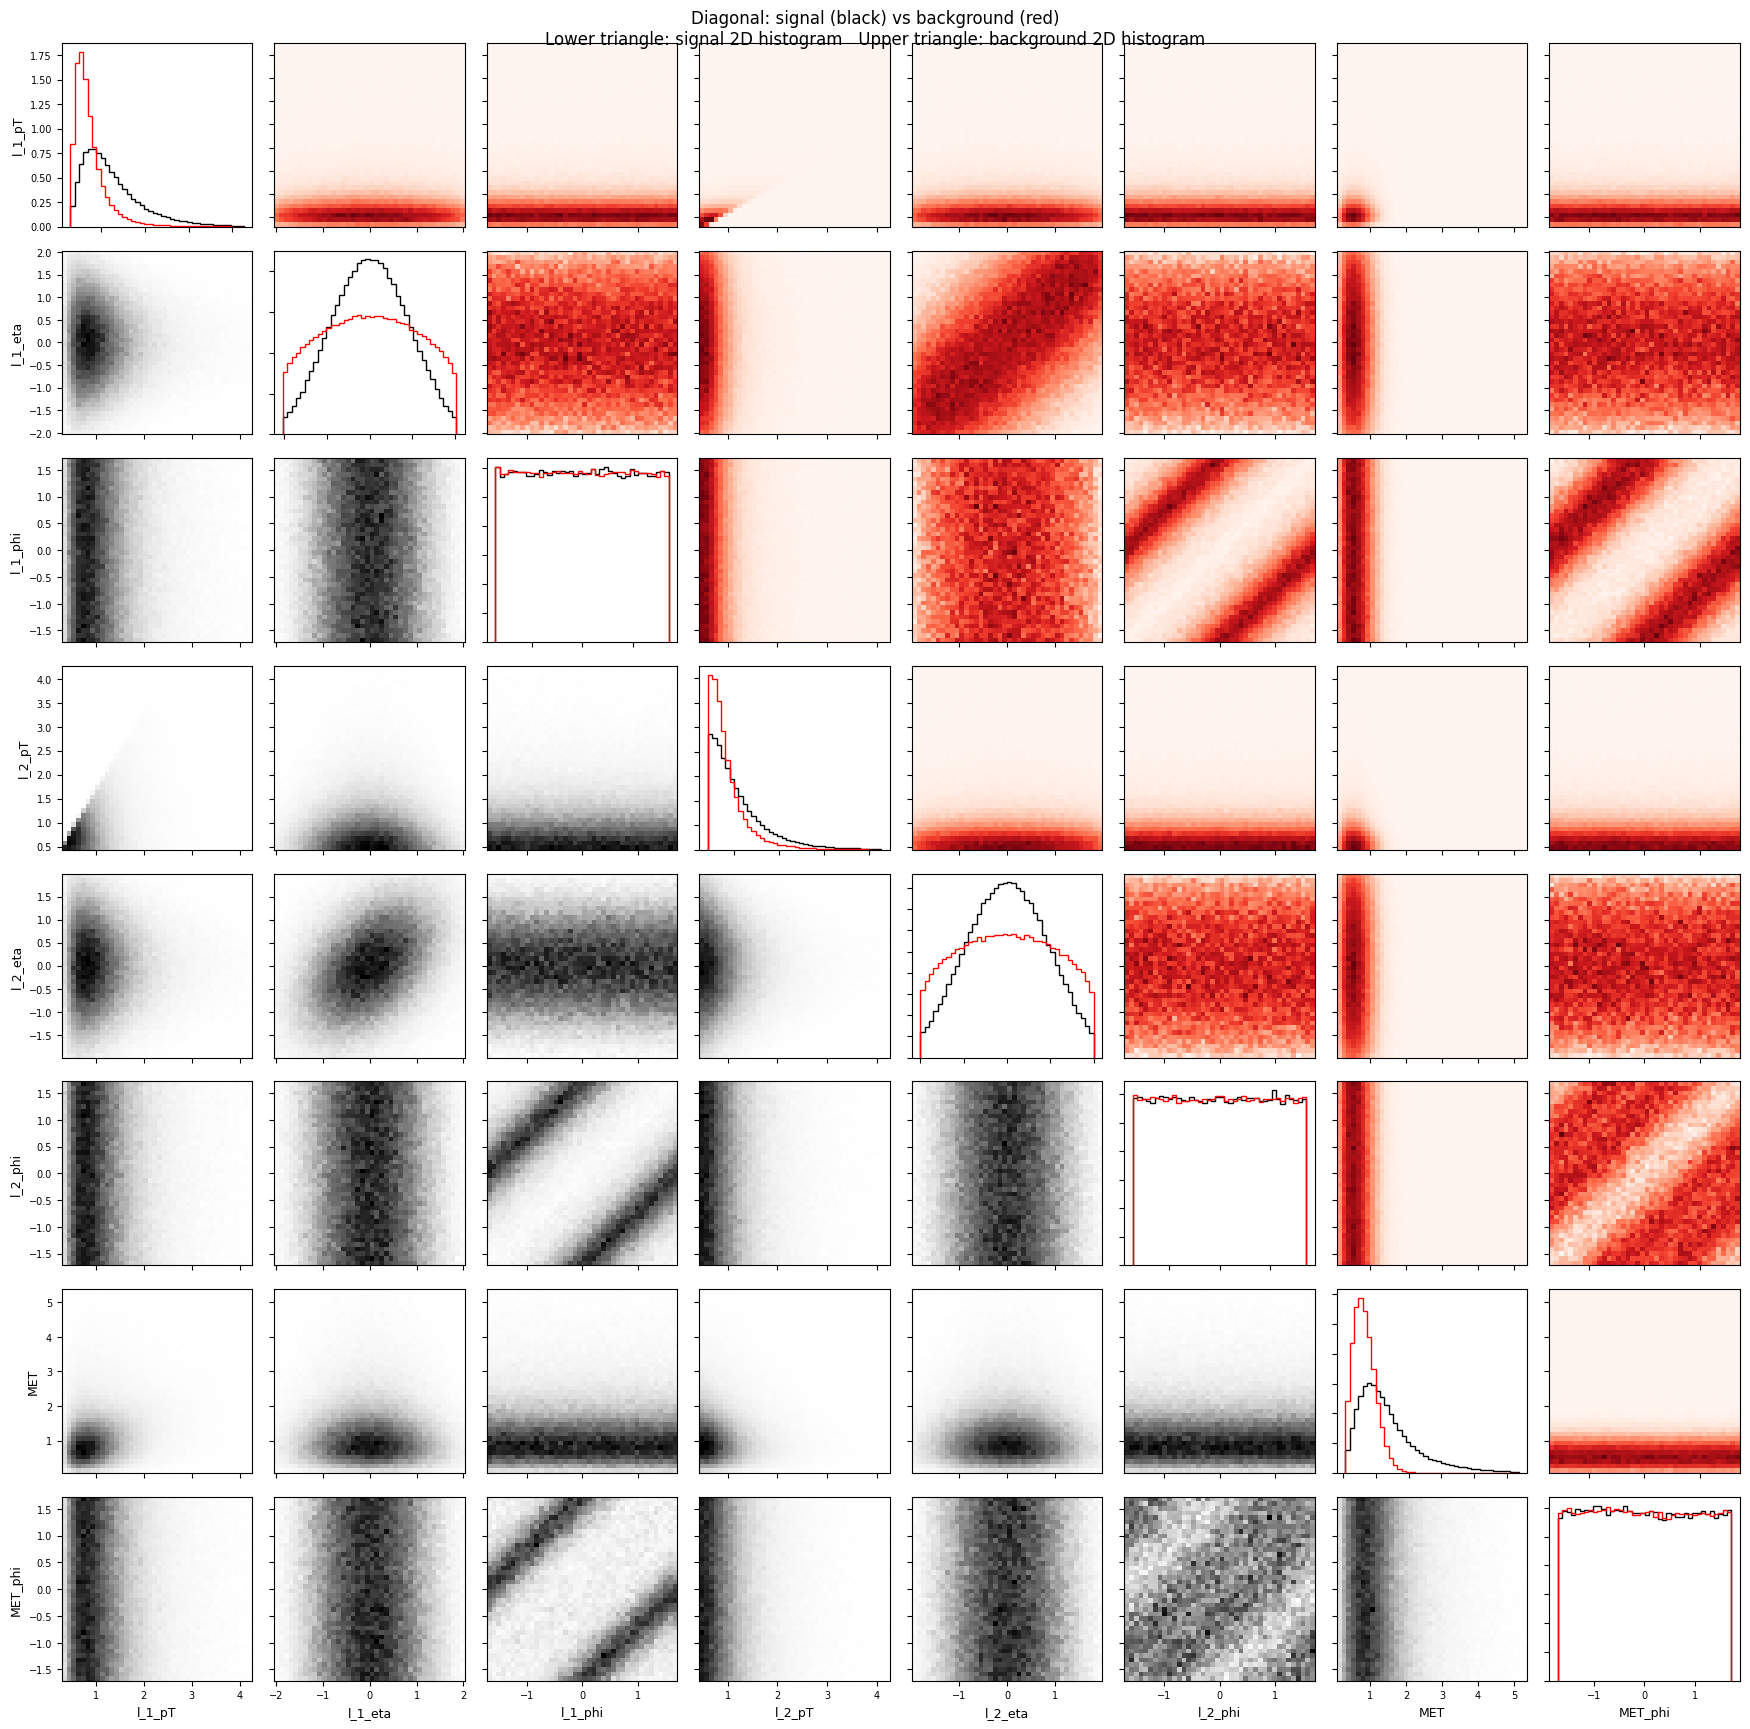

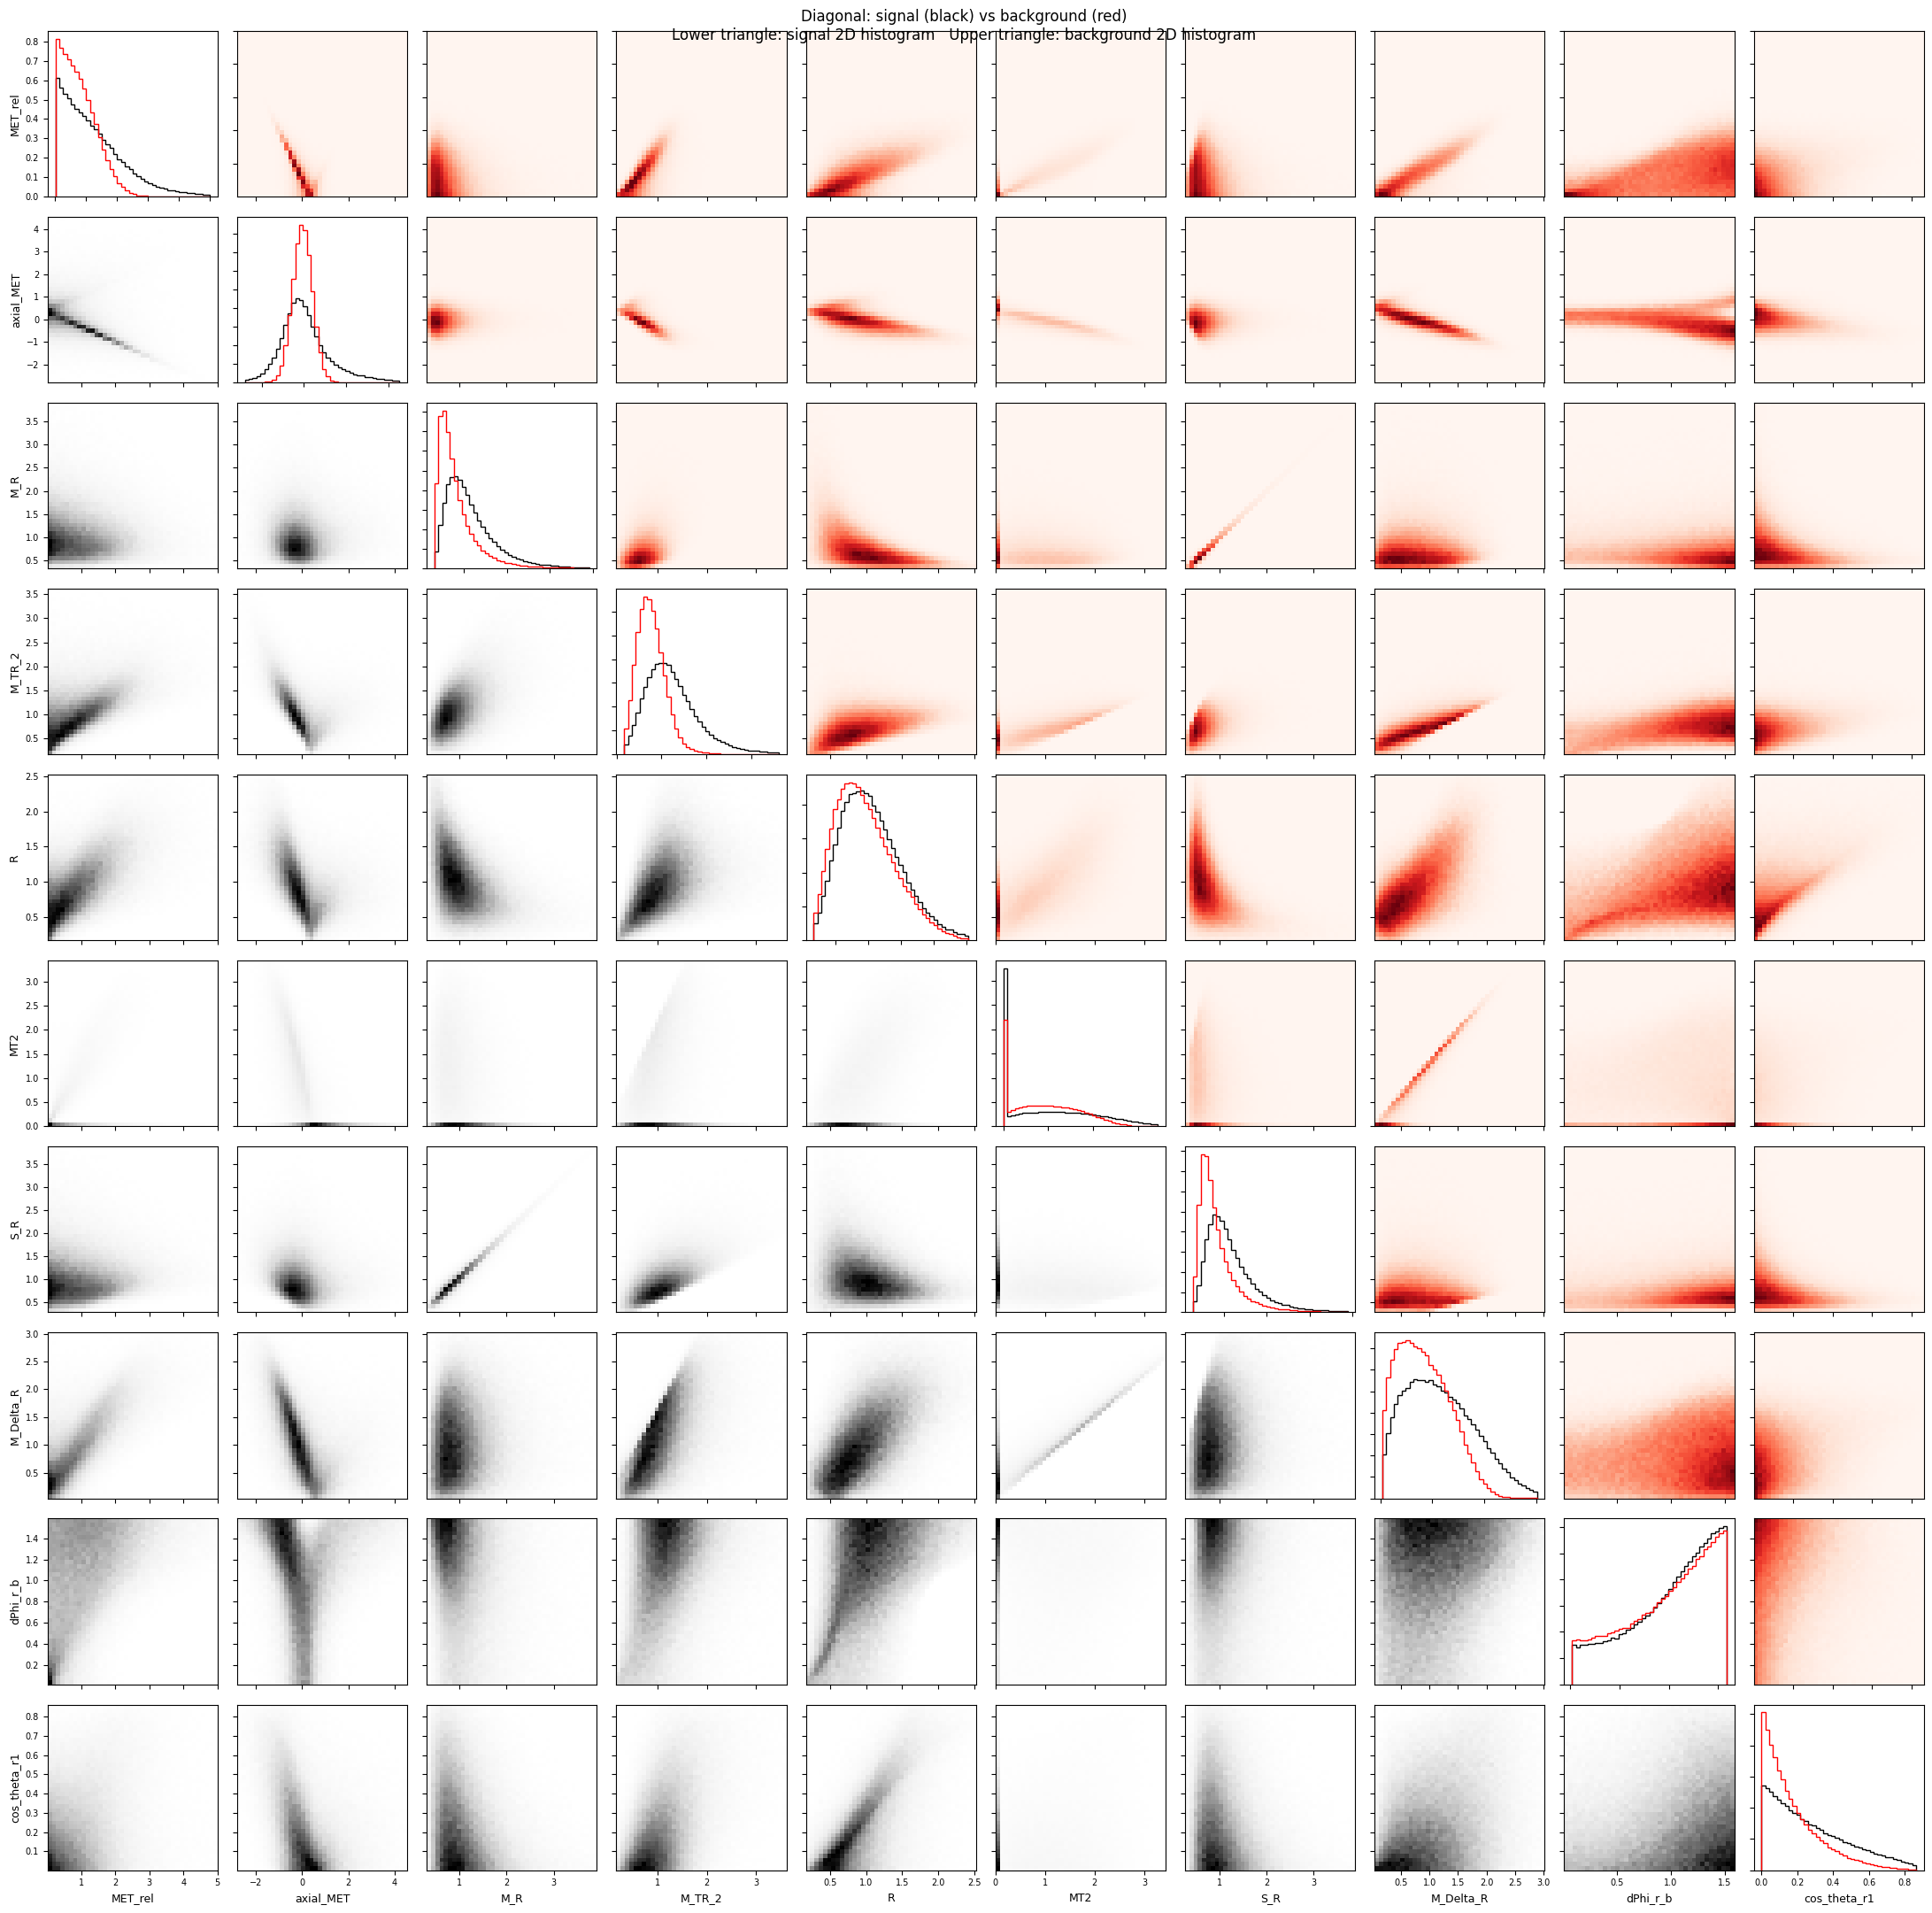

In [24]:
def fast_pair_plot(sig, bkg, var_list, bins=40):
    n = len(var_list)
    # Speed-up 1: compute the bin edges once per variable and reuse them
    edges = {}
    for v in var_list:
        lo, hi = np.percentile(np.concatenate([sig[v], bkg[v]]), [0.5, 99.5])
        edges[v] = np.linspace(lo, hi, bins + 1)
    # Speed-up 2: convert to plain numpy arrays once (faster than pandas columns)
    S = {v: sig[v].to_numpy() for v in var_list}
    B = {v: bkg[v].to_numpy() for v in var_list}

    fig, axes = plt.subplots(n, n, figsize=(2.2 * n, 2.2 * n))
    for i, y_var in enumerate(var_list):
        for j, x_var in enumerate(var_list):
            ax = axes[i, j]
            if i == j:
                # Speed-up 3: numpy counts the histogram, matplotlib only draws it
                hs, _ = np.histogram(S[x_var], bins=edges[x_var], density=True)
                hb, _ = np.histogram(B[x_var], bins=edges[x_var], density=True)
                ax.stairs(hs, edges[x_var], color="black")
                ax.stairs(hb, edges[x_var], color="red")
            else:
                # Speed-up 4: 2D histogram instead of drawing every point
                data = S if i > j else B          # lower triangle = signal, upper = background
                h, xe, ye = np.histogram2d(data[x_var], data[y_var],
                                           bins=[edges[x_var], edges[y_var]])
                ax.pcolormesh(xe, ye, h.T, cmap="Greys" if i > j else "Reds")
            if i == n - 1: ax.set_xlabel(x_var, fontsize=9)
            else: ax.set_xticklabels([])
            if j == 0: ax.set_ylabel(y_var, fontsize=9)
            else: ax.set_yticklabels([])
            ax.tick_params(labelsize=7)
    fig.suptitle("Diagonal: signal (black) vs background (red)\n"
                 "Lower triangle: signal 2D histogram   Upper triangle: background 2D histogram",
                 fontsize=12)
    plt.tight_layout()
    plt.show()

# no sampling needed - this handles all 500,000 events
fast_pair_plot(df_sig, df_bkg, RawNames)
fast_pair_plot(df_sig, df_bkg, VarNames[9:])

The original pair plot function was slow because each off-diagonal panel used a scatter plot, which draws every single event as its own point. With 8 variables there are 56 scatter panels, so even a 5,000-event sample means drawing over half a million points, and many of them overlap into solid blobs that hide how dense the data really is. To speed this up, I replaced the scatter plots with 2D histograms using np.histogram2d, which divides each panel into a 40×40 grid, counts how many events fall in each square, and colors the squares by those counts. Because matplotlib only has to draw 1,600 squares per panel no matter how many events there are, the function can now use all 500,000 events instead of a small sample. I also computed the bin edges once per variable and reused them, and let numpy do the counting with np.histogram before plotting, since numpy is much faster than matplotlib's hist at that step. A further way to speed up pair plots would be to compute all of the 1D and 2D histograms once, store them, and then make plots only from those saved counts. That way, changing the styling or layout of the figure would not require looping over the full dataset again.

In [25]:
def overlap(var, bins=100):
    edges = np.linspace(*np.percentile(df[var], [0.5, 99.5]), bins + 1)
    hs, _ = np.histogram(df_sig[var], bins=edges)
    hb, _ = np.histogram(df_bkg[var], bins=edges)
    # shared area under both normalized histograms: 1 = identical, 0 = fully separated
    return np.minimum(hs / hs.sum(), hb / hb.sum()).sum()

scores = {v: overlap(v) for v in VarNames[1:]}
for v, s in sorted(scores.items(), key=lambda kv: kv[1]):
    print(f"{v:15s} overlap = {s:.3f}")

MET             overlap = 0.580
l_1_pT          overlap = 0.594
M_TR_2          overlap = 0.599
axial_MET       overlap = 0.667
S_R             overlap = 0.688
M_R             overlap = 0.689
MET_rel         overlap = 0.785
cos_theta_r1    overlap = 0.789
M_Delta_R       overlap = 0.802
MT2             overlap = 0.804
l_2_pT          overlap = 0.806
l_1_eta         overlap = 0.826
l_2_eta         overlap = 0.848
R               overlap = 0.914
dPhi_r_b        overlap = 0.968
MET_phi         overlap = 0.989
l_1_phi         overlap = 0.989
l_2_phi         overlap = 0.990


### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [26]:
%pip install tabulate


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [27]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [28]:
import numpy as np

HighLevel = VarNames[9:]
AllVars = VarNames[1:]          # everything except the "signal" label

def get_matrices(data, var_list):
    X = data[var_list].to_numpy()
    cov = np.cov(X, rowvar=False)        # rowvar=False: each COLUMN is a variable
    corr = np.corrcoef(X, rowvar=False)
    return cov, corr

cov_all,  corr_all  = get_matrices(df, AllVars)
cov_low,  corr_low  = get_matrices(df, RawNames)
cov_high, corr_high = get_matrices(df, HighLevel)

print(cov_all.shape, cov_low.shape, cov_high.shape)

(18, 18) (8, 8) (10, 10)


In [29]:
from IPython.display import HTML, display
import tabulate

def show_table(M, var_list, title, fmt):
    rows = [[var] + list(row) for var, row in zip(var_list, M)]   # variable name at the start of each row
    display(HTML(f"<h4>{title}</h4>"))
    display(HTML(tabulate.tabulate(rows, headers=[""] + var_list,
                                   tablefmt="html", floatfmt=fmt)))

show_table(cov_all,   AllVars,   "Covariance matrix: all observables",      ".3g")
show_table(corr_all,  AllVars,   "Correlation matrix: all observables",     ".2f")
show_table(cov_low,   RawNames,  "Covariance matrix: low-level features",   ".3g")
show_table(corr_low,  RawNames,  "Correlation matrix: low-level features",  ".2f")
show_table(cov_high,  HighLevel, "Covariance matrix: high-level features",  ".3g")
show_table(corr_high, HighLevel, "Correlation matrix: high-level features", ".2f")

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1.00,-0.00,0.00,0.68,-0.00,0.00,0.38,-0.00,0.16,-0.01,0.85,0.72,-0.19,-0.02,0.81,0.23,-0.16,0.16
l_1_eta,-0.00,1.00,-0.00,-0.00,0.41,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
l_1_phi,0.00,-0.00,1.00,0.00,0.00,-0.27,0.00,-0.18,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
l_2_pT,0.68,-0.00,0.00,1.00,-0.00,0.00,0.14,-0.00,-0.00,0.08,0.80,0.43,-0.32,-0.12,0.80,0.01,-0.01,-0.22
l_2_eta,-0.00,0.41,0.00,-0.00,1.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00
l_2_phi,0.00,-0.00,-0.27,0.00,0.00,1.00,-0.00,-0.04,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00,0.00
MET,0.38,-0.00,0.00,0.14,0.00,-0.00,1.00,-0.00,0.70,0.18,0.26,0.72,0.46,0.21,0.31,0.58,0.38,0.42
MET_phi,-0.00,-0.00,-0.18,-0.00,-0.00,-0.04,-0.00,1.00,-0.01,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00
MET_rel,0.16,-0.00,0.00,-0.00,0.00,0.00,0.70,-0.01,1.00,-0.13,0.08,0.58,0.59,0.54,0.15,0.75,0.38,0.32
axial_MET,-0.01,-0.00,-0.00,0.08,-0.00,-0.00,0.18,-0.00,-0.13,1.00,0.03,-0.32,-0.38,-0.54,-0.07,-0.37,-0.06,-0.27


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1.00,-0.00,0.00,0.68,-0.00,0.00,0.38,-0.00
l_1_eta,-0.00,1.00,-0.00,-0.00,0.41,-0.00,-0.00,-0.00
l_1_phi,0.00,-0.00,1.00,0.00,0.00,-0.27,0.00,-0.18
l_2_pT,0.68,-0.00,0.00,1.00,-0.00,0.00,0.14,-0.00
l_2_eta,-0.00,0.41,0.00,-0.00,1.00,0.00,0.00,-0.00
l_2_phi,0.00,-0.00,-0.27,0.00,0.00,1.00,-0.00,-0.04
MET,0.38,-0.00,0.00,0.14,0.00,-0.00,1.00,-0.00
MET_phi,-0.00,-0.00,-0.18,-0.00,-0.00,-0.04,-0.00,1.00


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537
M_R,0.0437,0.0171,0.392,0.21,-0.113,-0.0365,0.38,0.0739,-0.029,-0.0143
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.0581,0.0517
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.0834,0.165,0.0871,0.0582
MT2,0.409,-0.461,-0.0365,0.189,0.232,0.738,-0.011,0.433,0.0209,0.0446
S_R,0.0823,-0.0414,0.38,0.228,-0.0834,-0.011,0.382,0.0958,-0.00346,-0.0104
M_Delta_R,0.415,-0.233,0.0739,0.242,0.165,0.433,0.0958,0.389,0.0422,0.0392
dPhi_r_b,0.146,-0.0251,-0.029,0.0581,0.0871,0.0209,-0.00346,0.0422,0.19,0.00908
cos_theta_r1,0.0553,-0.0537,-0.0143,0.0517,0.0582,0.0446,-0.0104,0.0392,0.00908,0.0388


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1.00,-0.13,0.08,0.58,0.59,0.54,0.15,0.75,0.38,0.32
axial_MET,-0.13,1.00,0.03,-0.32,-0.38,-0.54,-0.07,-0.37,-0.06,-0.27
M_R,0.08,0.03,1.00,0.58,-0.38,-0.07,0.98,0.19,-0.11,-0.12
M_TR_2,0.58,-0.32,0.58,1.00,0.38,0.38,0.64,0.67,0.23,0.45
R,0.59,-0.38,-0.38,0.38,1.00,0.57,-0.29,0.56,0.42,0.63
MT2,0.54,-0.54,-0.07,0.38,0.57,1.00,-0.02,0.81,0.06,0.26
S_R,0.15,-0.07,0.98,0.64,-0.29,-0.02,1.00,0.25,-0.01,-0.09
M_Delta_R,0.75,-0.37,0.19,0.67,0.56,0.81,0.25,1.00,0.16,0.32
dPhi_r_b,0.38,-0.06,-0.11,0.23,0.42,0.06,-0.01,0.16,1.00,0.11
cos_theta_r1,0.32,-0.27,-0.12,0.45,0.63,0.26,-0.09,0.32,0.11,1.00


In [30]:
def correlation_report(data, var_list, label="", fmt_cov=".3g", fmt_corr=".2f"):
    """Compute and display the covariance and correlation matrices for var_list."""
    cov, corr = get_matrices(data, var_list)                      # step b
    show_table(cov,  var_list, f"Covariance matrix: {label}",  fmt_cov)   # step c
    show_table(corr, var_list, f"Correlation matrix: {label}", fmt_corr)
    return cov, corr

# examples of using it
correlation_report(df, AllVars,   "all observables")
correlation_report(df, RawNames,  "low-level features")
correlation_report(df, HighLevel, "high-level features")

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1.00,-0.00,0.00,0.68,-0.00,0.00,0.38,-0.00,0.16,-0.01,0.85,0.72,-0.19,-0.02,0.81,0.23,-0.16,0.16
l_1_eta,-0.00,1.00,-0.00,-0.00,0.41,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
l_1_phi,0.00,-0.00,1.00,0.00,0.00,-0.27,0.00,-0.18,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
l_2_pT,0.68,-0.00,0.00,1.00,-0.00,0.00,0.14,-0.00,-0.00,0.08,0.80,0.43,-0.32,-0.12,0.80,0.01,-0.01,-0.22
l_2_eta,-0.00,0.41,0.00,-0.00,1.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00
l_2_phi,0.00,-0.00,-0.27,0.00,0.00,1.00,-0.00,-0.04,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00,0.00
MET,0.38,-0.00,0.00,0.14,0.00,-0.00,1.00,-0.00,0.70,0.18,0.26,0.72,0.46,0.21,0.31,0.58,0.38,0.42
MET_phi,-0.00,-0.00,-0.18,-0.00,-0.00,-0.04,-0.00,1.00,-0.01,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00
MET_rel,0.16,-0.00,0.00,-0.00,0.00,0.00,0.70,-0.01,1.00,-0.13,0.08,0.58,0.59,0.54,0.15,0.75,0.38,0.32
axial_MET,-0.01,-0.00,-0.00,0.08,-0.00,-0.00,0.18,-0.00,-0.13,1.00,0.03,-0.32,-0.38,-0.54,-0.07,-0.37,-0.06,-0.27


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1.00,-0.00,0.00,0.68,-0.00,0.00,0.38,-0.00
l_1_eta,-0.00,1.00,-0.00,-0.00,0.41,-0.00,-0.00,-0.00
l_1_phi,0.00,-0.00,1.00,0.00,0.00,-0.27,0.00,-0.18
l_2_pT,0.68,-0.00,0.00,1.00,-0.00,0.00,0.14,-0.00
l_2_eta,-0.00,0.41,0.00,-0.00,1.00,0.00,0.00,-0.00
l_2_phi,0.00,-0.00,-0.27,0.00,0.00,1.00,-0.00,-0.04
MET,0.38,-0.00,0.00,0.14,0.00,-0.00,1.00,-0.00
MET_phi,-0.00,-0.00,-0.18,-0.00,-0.00,-0.04,-0.00,1.00


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537
M_R,0.0437,0.0171,0.392,0.21,-0.113,-0.0365,0.38,0.0739,-0.029,-0.0143
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.0581,0.0517
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.0834,0.165,0.0871,0.0582
MT2,0.409,-0.461,-0.0365,0.189,0.232,0.738,-0.011,0.433,0.0209,0.0446
S_R,0.0823,-0.0414,0.38,0.228,-0.0834,-0.011,0.382,0.0958,-0.00346,-0.0104
M_Delta_R,0.415,-0.233,0.0739,0.242,0.165,0.433,0.0958,0.389,0.0422,0.0392
dPhi_r_b,0.146,-0.0251,-0.029,0.0581,0.0871,0.0209,-0.00346,0.0422,0.19,0.00908
cos_theta_r1,0.0553,-0.0537,-0.0143,0.0517,0.0582,0.0446,-0.0104,0.0392,0.00908,0.0388


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1.00,-0.13,0.08,0.58,0.59,0.54,0.15,0.75,0.38,0.32
axial_MET,-0.13,1.00,0.03,-0.32,-0.38,-0.54,-0.07,-0.37,-0.06,-0.27
M_R,0.08,0.03,1.00,0.58,-0.38,-0.07,0.98,0.19,-0.11,-0.12
M_TR_2,0.58,-0.32,0.58,1.00,0.38,0.38,0.64,0.67,0.23,0.45
R,0.59,-0.38,-0.38,0.38,1.00,0.57,-0.29,0.56,0.42,0.63
MT2,0.54,-0.54,-0.07,0.38,0.57,1.00,-0.02,0.81,0.06,0.26
S_R,0.15,-0.07,0.98,0.64,-0.29,-0.02,1.00,0.25,-0.01,-0.09
M_Delta_R,0.75,-0.37,0.19,0.67,0.56,0.81,0.25,1.00,0.16,0.32
dPhi_r_b,0.38,-0.06,-0.11,0.23,0.42,0.06,-0.01,0.16,1.00,0.11
cos_theta_r1,0.32,-0.27,-0.12,0.45,0.63,0.26,-0.09,0.32,0.11,1.00


(array([[ 0.79048911, -0.1198512 ,  0.04368455,  0.30199264,  0.24882357,
          0.40877889,  0.08231538,  0.41474304,  0.1464394 ,  0.05531787],
        [-0.1198512 ,  1.00537396,  0.01713455, -0.18501679, -0.18090014,
         -0.46099861, -0.04138282, -0.23307398, -0.02511279, -0.05373485],
        [ 0.04368455,  0.01713455,  0.39216708,  0.20987467, -0.11290414,
         -0.03654441,  0.37976344,  0.07393003, -0.02896168, -0.01434118],
        [ 0.30199264, -0.18501679,  0.20987467,  0.33782719,  0.10401425,
          0.18916951,  0.2281247 ,  0.24186516,  0.05813297,  0.05166586],
        [ 0.24882357, -0.18090014, -0.11290414,  0.10401425,  0.22157807,
          0.23210005, -0.08335872,  0.16548304,  0.08709136,  0.05816081],
        [ 0.40877889, -0.46099861, -0.03654441,  0.18916951,  0.23210005,
          0.73766054, -0.01103752,  0.43289693,  0.02089723,  0.04462891],
        [ 0.08231538, -0.04138282,  0.37976344,  0.2281247 , -0.08335872,
         -0.01103752,  0.3820146

## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [31]:

AllVars = VarNames[1:]
kinds = ["x>xc", "x<xc", "|x-mu|>xc", "|x-mu|<xc"]

def efficiency(values, xc, kind, mu=0.0):
    """Fraction of events that pass the cut, for an array of cut values xc."""
    if kind.startswith("|"):
        values = np.abs(values - mu)
    v = np.sort(values)
    n = len(v)
    if kind in ("x>xc", "|x-mu|>xc"):
        return 1 - np.searchsorted(v, xc, side="right") / n
    else:
        return np.searchsorted(v, xc, side="left") / n

def scan_range(var, kind, mu, npts=200):
    """The x_c values to try (skipping extreme tails)."""
    x = df[var].to_numpy()
    if kind.startswith("|"):
        x = np.abs(x - mu)
    lo, hi = np.percentile(x, [0.5, 99.5])
    return np.linspace(lo, hi, npts)

best_cut = {}
rows = []
for var in AllVars:
    mu = df[var].mean()
    s = df_sig[var].to_numpy()
    b = df_bkg[var].to_numpy()
    scores = {}
    for kind in kinds:
        xc = scan_range(var, kind, mu)
        # best possible gap between keeping signal and keeping background
        scores[kind] = np.max(efficiency(s, xc, kind, mu) - efficiency(b, xc, kind, mu))
    choice = max(scores, key=scores.get)
    best_cut[var] = (choice, mu)
    rows.append([var, choice, f"{mu:.3f}", f"{scores[choice]:.3f}"])

display(HTML(tabulate.tabulate(rows, headers=["Observable", "Best criterion", "μ", "max(TPR − FPR)"],
                               tablefmt="html")))

Observable,Best criterion,μ,max(TPR − FPR)
l_1_pT,x>xc,1,0.409
l_1_eta,|x-mu|<xc,0,0.178
l_1_phi,|x-mu|<xc,-0.002,0.002
l_2_pT,x>xc,0.999,0.195
l_2_eta,|x-mu|<xc,0.001,0.155
l_2_phi,|x-mu|>xc,-0,0.002
MET,x>xc,1.001,0.424
MET_phi,|x-mu|<xc,0,0.003
MET_rel,x>xc,1.002,0.222
axial_MET,|x-mu|>xc,0.003,0.344


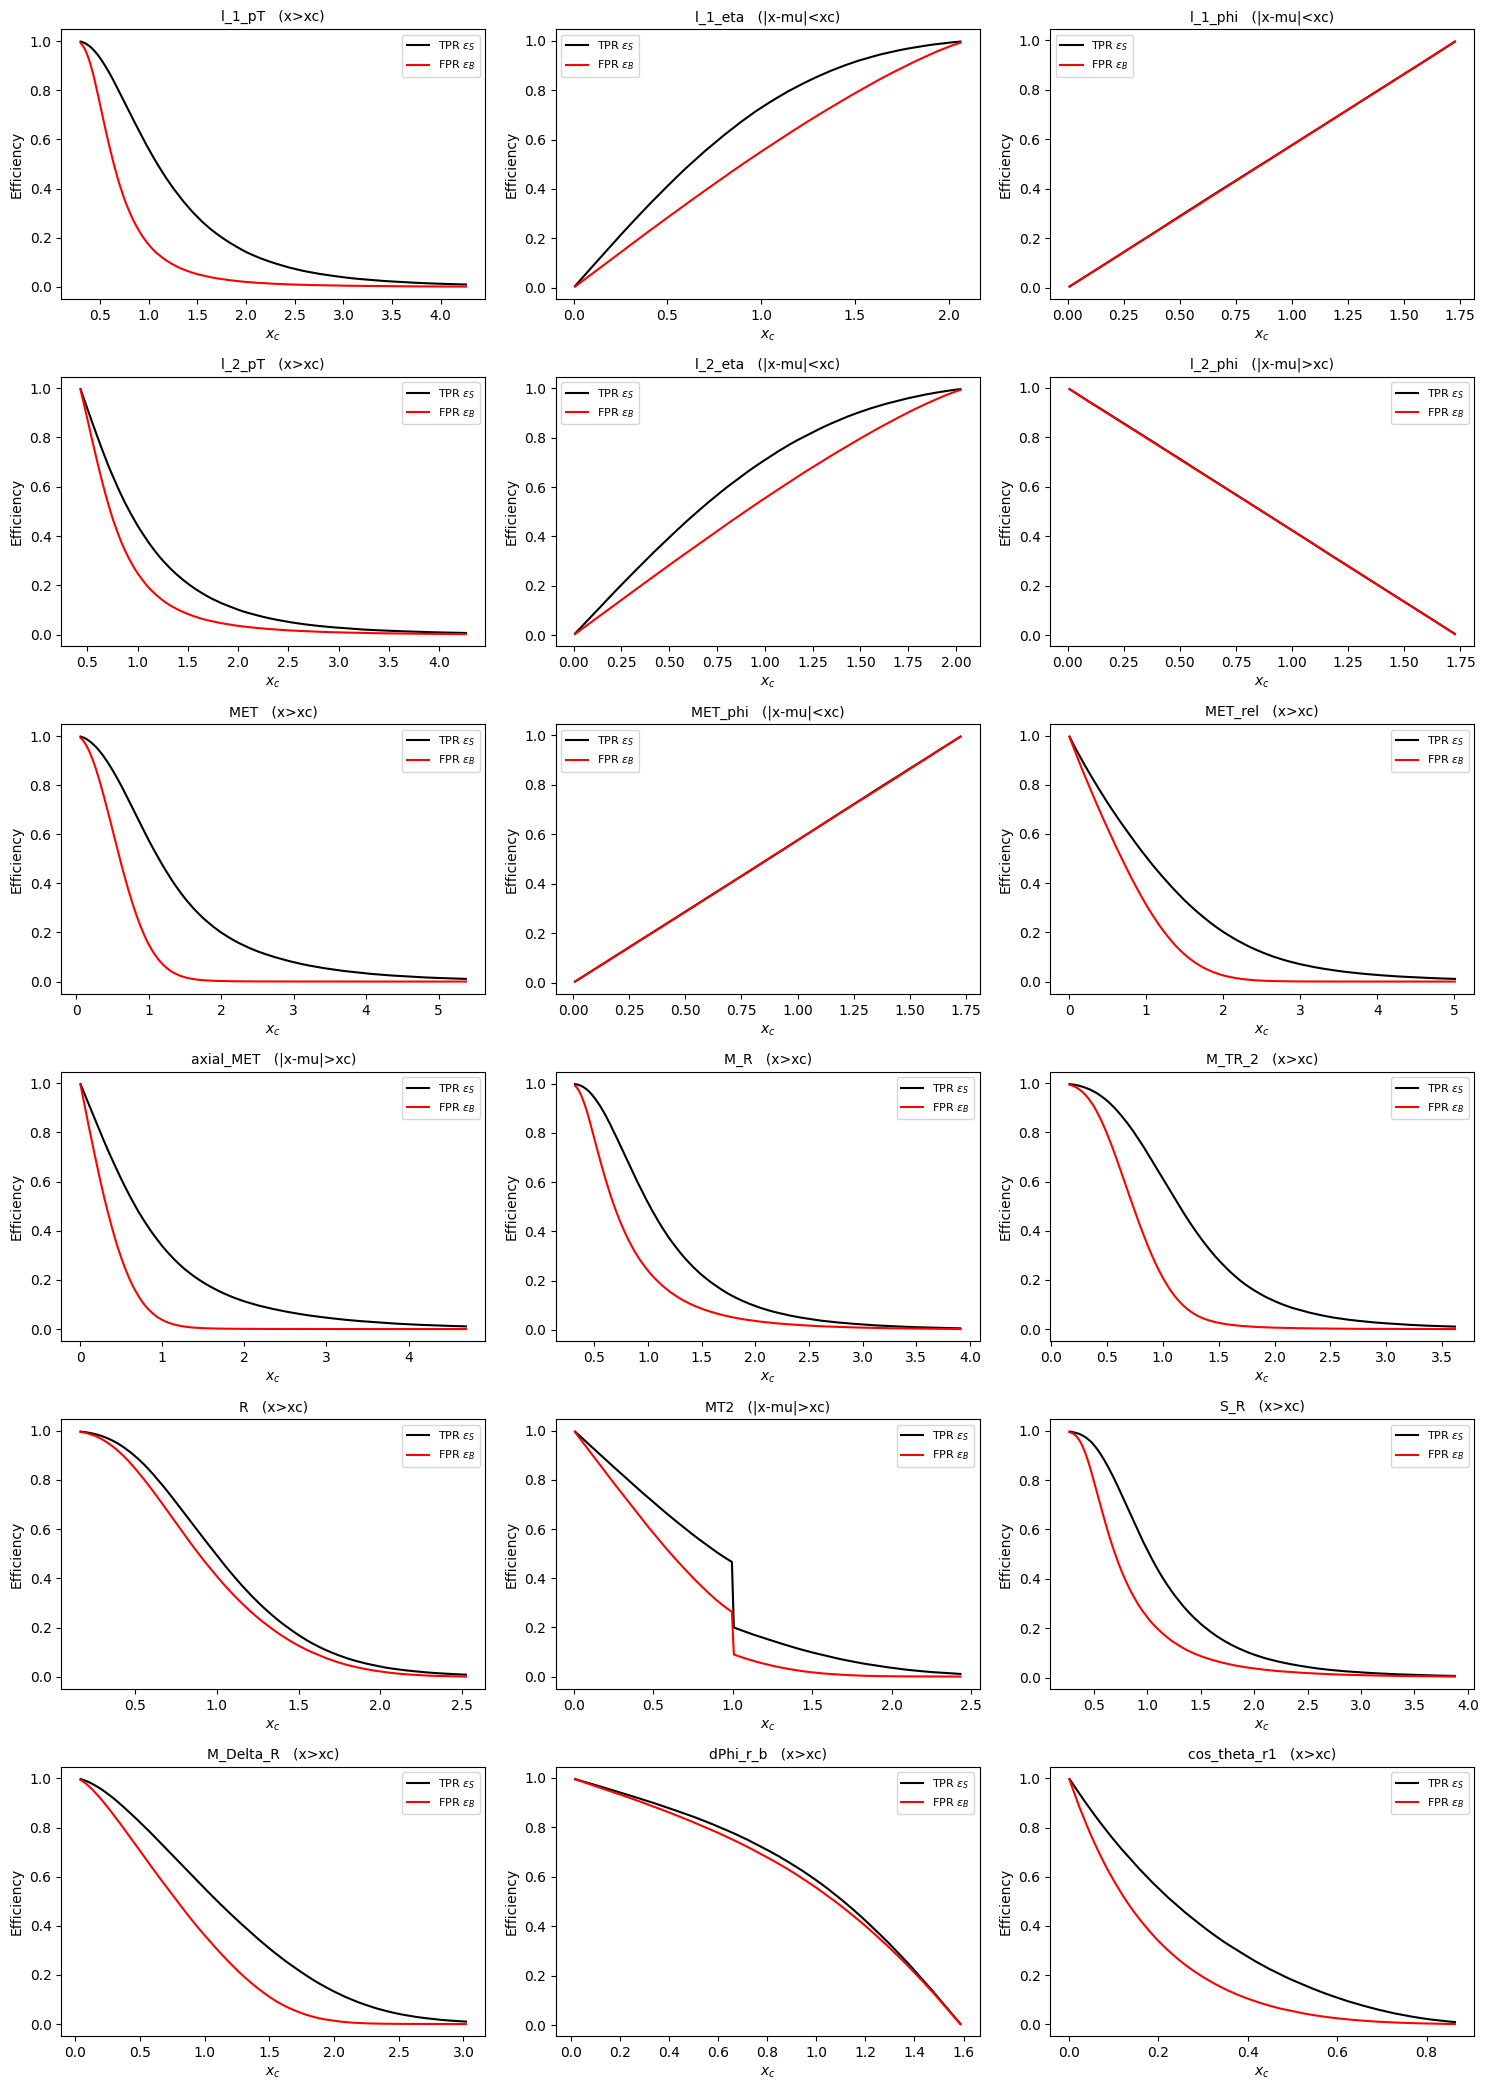

In [32]:
n = len(AllVars)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax, var in zip(axes, AllVars):
    kind, mu = best_cut[var]
    xc = scan_range(var, kind, mu)
    ax.plot(xc, efficiency(df_sig[var].to_numpy(), xc, kind, mu), color="black", label=r"TPR $\epsilon_S$")
    ax.plot(xc, efficiency(df_bkg[var].to_numpy(), xc, kind, mu), color="red",   label=r"FPR $\epsilon_B$")
    ax.set_title(f"{var}   ({kind})", fontsize=10)
    ax.set_xlabel(r"$x_c$")
    ax.set_ylabel("Efficiency")
    ax.legend(fontsize=8)

for ax in axes[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

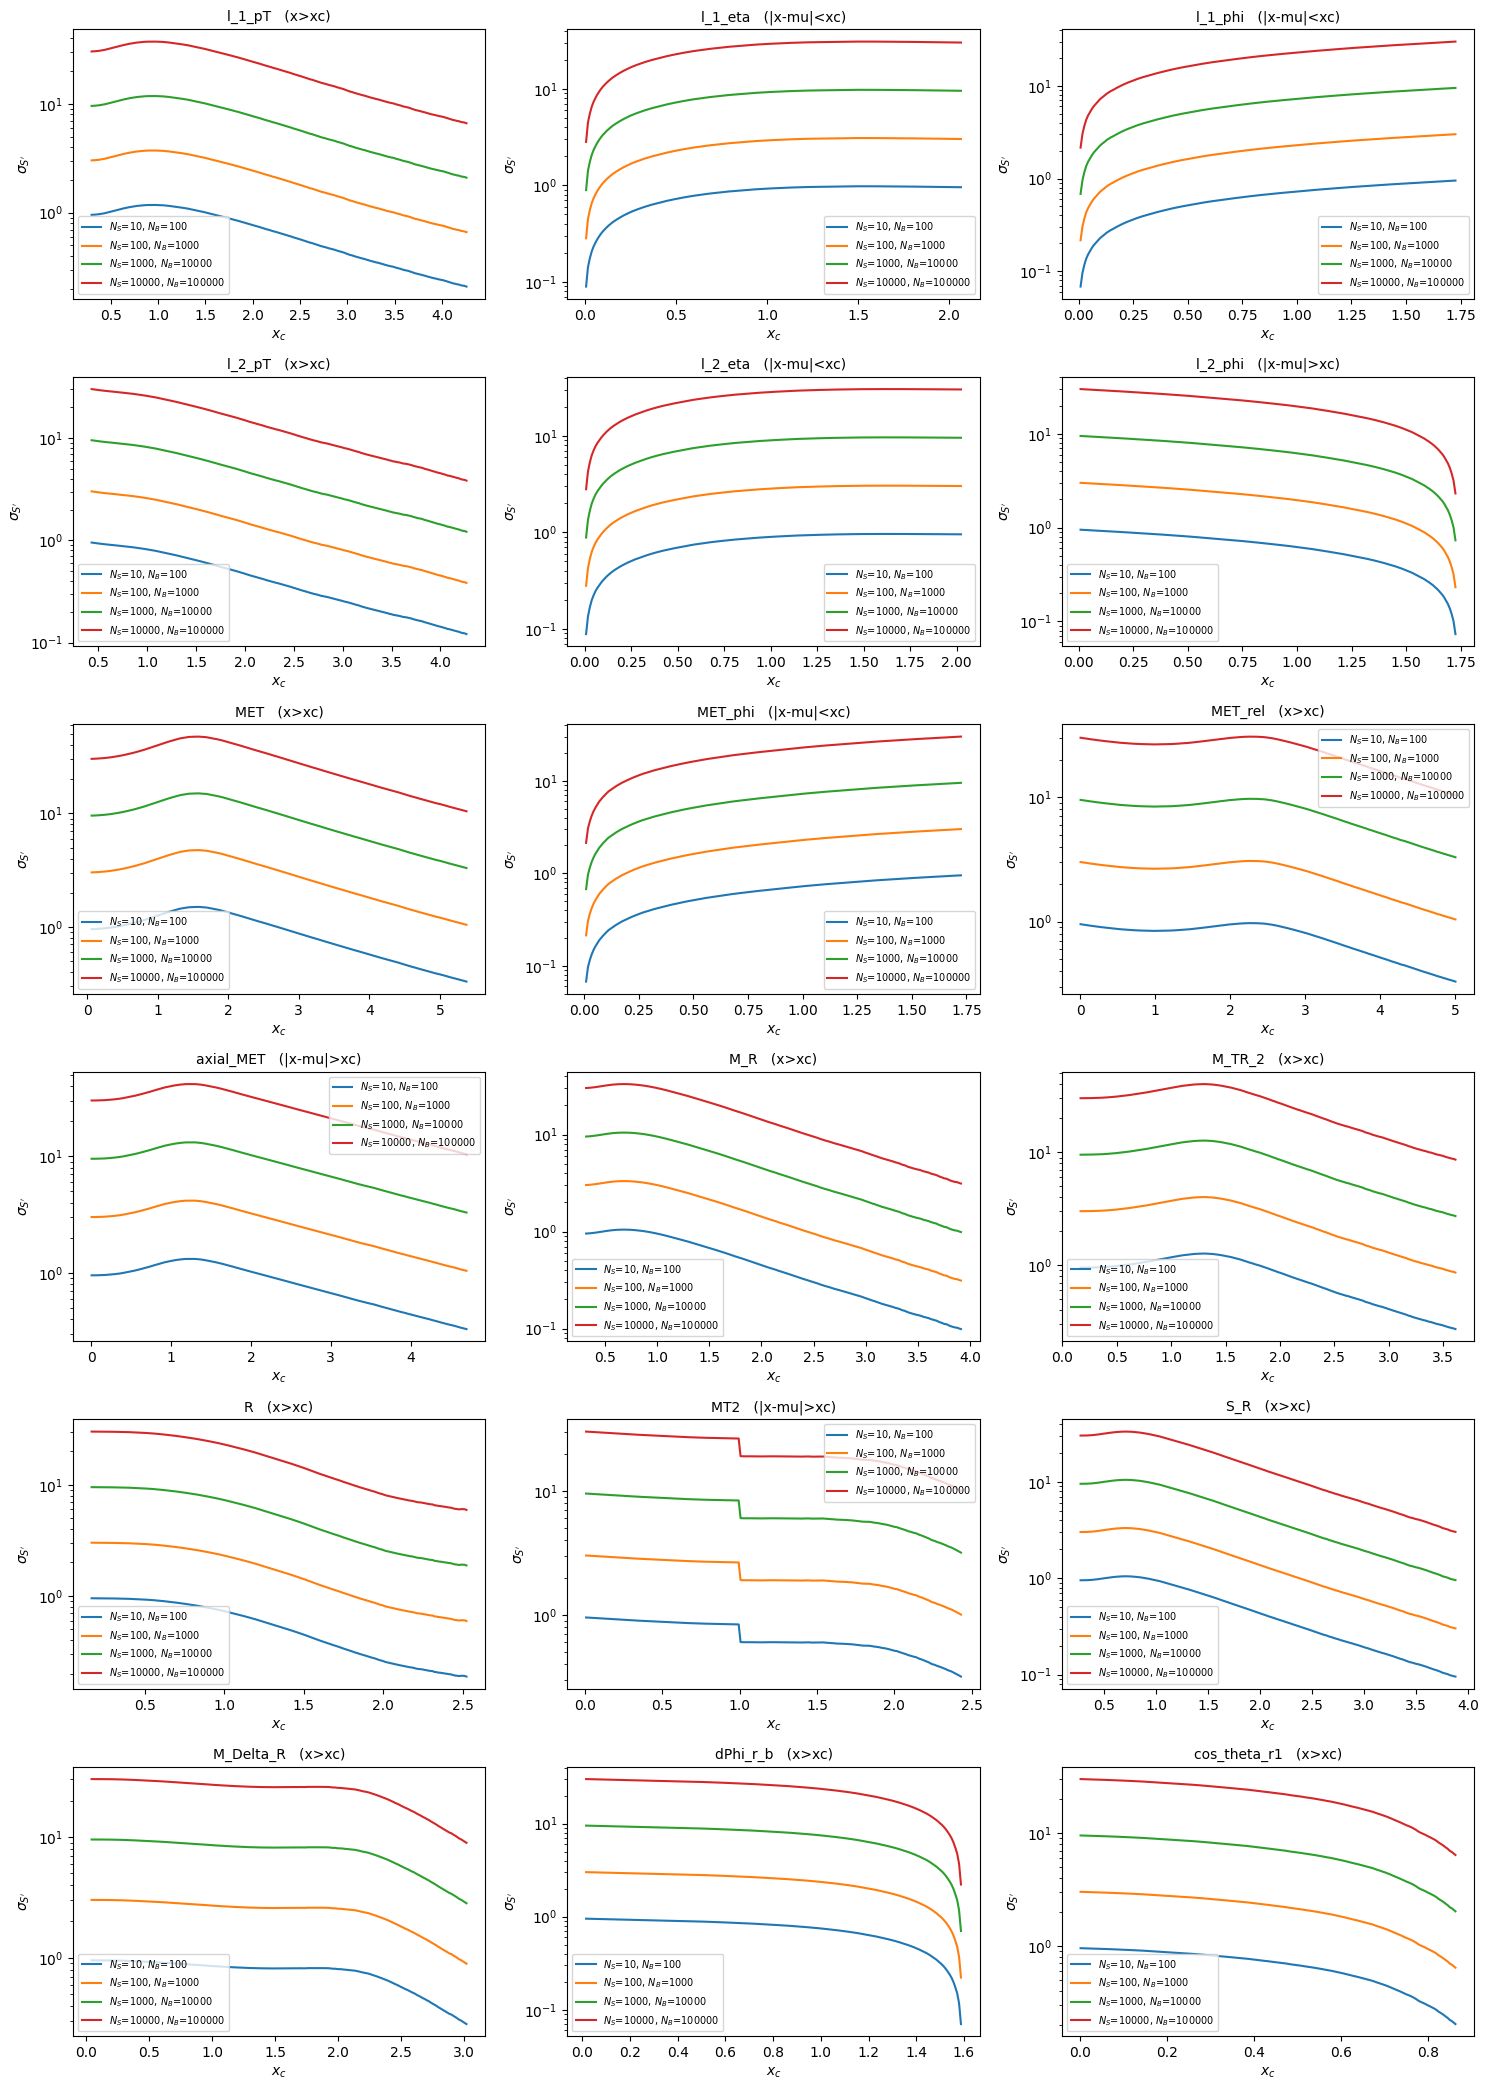

Observable,Criterion,N_S,N_B,best x_c,max σ,σ with no cut
l_1_pT,x>xc,10,100,0.956,1.18,0.95
l_1_pT,x>xc,100,1000,0.956,3.72,3.02
l_1_pT,x>xc,1000,10000,0.956,11.77,9.53
l_1_pT,x>xc,10000,100000,0.956,37.21,30.15
l_1_eta,|x-mu|<xc,10,100,1.516,0.98,0.95
l_1_eta,|x-mu|<xc,100,1000,1.516,3.09,3.02
l_1_eta,|x-mu|<xc,1000,10000,1.516,9.76,9.53
l_1_eta,|x-mu|<xc,10000,100000,1.516,30.87,30.15
l_1_phi,|x-mu|<xc,10,100,1.726,0.95,0.95
l_1_phi,|x-mu|<xc,100,1000,1.726,3.01,3.02


In [33]:
scenarios = [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]

def significance(eS, eB, NS, NB):
    nS = eS * NS          # N'_S
    nB = eB * NB          # N'_B
    denom = np.sqrt(nS + nB)
    return np.divide(nS, denom, out=np.zeros_like(nS, dtype=float), where=denom > 0)

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = axes.flatten()
best_xc = []

for ax, var in zip(axes, AllVars):
    kind, mu = best_cut[var]
    xc = scan_range(var, kind, mu)
    eS = efficiency(df_sig[var].to_numpy(), xc, kind, mu)
    eB = efficiency(df_bkg[var].to_numpy(), xc, kind, mu)
    for NS, NB in scenarios:
        sig = significance(eS, eB, NS, NB)
        ax.plot(xc, sig, label=f"$N_S$={NS}, $N_B$={NB}")
        i = np.argmax(sig)
        best_xc.append([var, kind, NS, NB, f"{xc[i]:.3f}", f"{sig[i]:.2f}", f"{NS/np.sqrt(NS+NB):.2f}"])
    ax.set_yscale("log")    # the scenarios differ by a lot, log scale shows all 4
    ax.set_title(f"{var}   ({kind})", fontsize=10)
    ax.set_xlabel(r"$x_c$")
    ax.set_ylabel(r"$\sigma_{S'}$")
    ax.legend(fontsize=7)

for ax in axes[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

# summary table: best cut value and significance for every observable + scenario
display(HTML(tabulate.tabulate(best_xc,
        headers=["Observable", "Criterion", "N_S", "N_B", "best x_c", "max σ", "σ with no cut"],
        tablefmt="html")))

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [34]:
from tabulate import tabulate as tab

def passes(values, kind, mu, xc):
    """True/False for each event: does it survive the cut?"""
    if kind.startswith("|"):
        values = np.abs(values - mu)
    return values > xc if ">" in kind else values < xc

def optimize(var, sig, bkg, NS, NB, sig_total, bkg_total):
    """Find the x_c that gives the highest significance for one observable."""
    kind, mu = best_cut[var]
    xc = scan_range(var, kind, mu)
    # efficiencies measured against the ORIGINAL sample size, so earlier cuts still count
    eS = efficiency(sig[var].to_numpy(), xc, kind, mu) * len(sig) / sig_total
    eB = efficiency(bkg[var].to_numpy(), xc, kind, mu) * len(bkg) / bkg_total
    s = significance(eS, eB, NS, NB)
    i = np.argmax(s)
    return xc[i], s[i], xc, s

n_pick = 3      # minimum 3 observables per scenario
selections = {}
rows = []
for NS, NB in scenarios:
    results = []
    for var in AllVars:
        xc_best, sig_best, _, _ = optimize(var, df_sig, df_bkg, NS, NB, len(df_sig), len(df_bkg))
        results.append((sig_best, var, xc_best))
    results.sort(reverse=True)                  # highest significance first
    chosen = [(var, best_cut[var][0], best_cut[var][1], xc) for _, var, xc in results[:n_pick]]
    selections[(NS, NB)] = chosen
    for var, kind, mu, xc in chosen:
        rows.append([f"N_S={NS}, N_B={NB}", var, kind, f"{xc:.3f}"])

display(HTML(tab(rows, headers=["Scenario", "Observable", "Criterion", "x_c"], tablefmt="html")))

Scenario,Observable,Criterion,x_c
"N_S=10, N_B=100",MET,x>xc,1.531
"N_S=10, N_B=100",axial_MET,|x-mu|>xc,1.255
"N_S=10, N_B=100",M_TR_2,x>xc,1.31
"N_S=100, N_B=1000",MET,x>xc,1.531
"N_S=100, N_B=1000",axial_MET,|x-mu|>xc,1.255
"N_S=100, N_B=1000",M_TR_2,x>xc,1.31
"N_S=1000, N_B=10000",MET,x>xc,1.531
"N_S=1000, N_B=10000",axial_MET,|x-mu|>xc,1.255
"N_S=1000, N_B=10000",M_TR_2,x>xc,1.31
"N_S=10000, N_B=100000",MET,x>xc,1.531


In [35]:
def cut_flow(cuts, NS, NB):
    sig_mask = np.ones(len(df_sig), dtype=bool)   # start: every event passes
    bkg_mask = np.ones(len(df_bkg), dtype=bool)
    rows = [["No cut", "1.0000", "1.0000", f"{NS:.1f}", f"{NB:.1f}", f"{NS/np.sqrt(NS+NB):.3f}"]]
    for var, kind, mu, xc in cuts:
        # &= means "must pass this cut AND every cut before it"
        sig_mask &= passes(df_sig[var].to_numpy(), kind, mu, xc)
        bkg_mask &= passes(df_bkg[var].to_numpy(), kind, mu, xc)
        eS = sig_mask.mean()
        eB = bkg_mask.mean()
        sigma = significance(eS, eB, NS, NB)
        rows.append([f"+ {var} ({kind.replace('xc', f'{xc:.3f}')})",
                     f"{eS:.4f}", f"{eB:.4f}", f"{eS*NS:.1f}", f"{eB*NB:.1f}", f"{sigma:.3f}"])
    return rows

for NS, NB in scenarios:
    display(HTML(f"<h4>Cut flow: N_S = {NS}, N_B = {NB}</h4>"))
    display(HTML(tab(cut_flow(selections[(NS, NB)], NS, NB),
                     headers=["Selection", "ε_S", "ε_B", "N'_S", "N'_B", "σ_S'"],
                     tablefmt="html")))

Selection,ε_S,ε_B,N'_S,N'_B,σ_S'
No cut,1,1,10,100,0.953
+ MET (x>1.531),0.3284,0.0151,3.3,1.5,1.5
+ axial_MET (|x-mu|>1.255),0.221,0.008,2.2,0.8,1.274
+ M_TR_2 (x>1.310),0.1555,0.0068,1.6,0.7,1.041


Selection,ε_S,ε_B,N'_S,N'_B,σ_S'
No cut,1,1,100,1000,3.015
+ MET (x>1.531),0.3284,0.0151,32.8,15.1,4.743
+ axial_MET (|x-mu|>1.255),0.221,0.008,22.1,8,4.029
+ M_TR_2 (x>1.310),0.1555,0.0068,15.6,6.8,3.291


Selection,ε_S,ε_B,N'_S,N'_B,σ_S'
No cut,1,1,1000,10000,9.535
+ MET (x>1.531),0.3284,0.0151,328.4,151,14.997
+ axial_MET (|x-mu|>1.255),0.221,0.008,221,79.9,12.742
+ M_TR_2 (x>1.310),0.1555,0.0068,155.5,67.8,10.408


Selection,ε_S,ε_B,N'_S,N'_B,σ_S'
No cut,1,1,10000,100000,30.151
+ MET (x>1.531),0.3284,0.0151,3283.6,1510.2,47.425
+ axial_MET (|x-mu|>1.255),0.221,0.008,2210.3,798.5,40.295
+ M_TR_2 (x>1.310),0.1555,0.0068,1555.4,678.1,32.912


Most correlated pair among chosen observables: ('MET', 'M_TR_2'), r = 0.72


Order,x_c from 5.3,σ (5.3 x_c),re-optimized x_c,σ (re-optimized)
"cut MET (x_c=1.531), then M_TR_2",1.31,4.034,0.167,4.737
"cut M_TR_2 (x_c=1.310), then MET",1.531,4.034,1.425,4.046


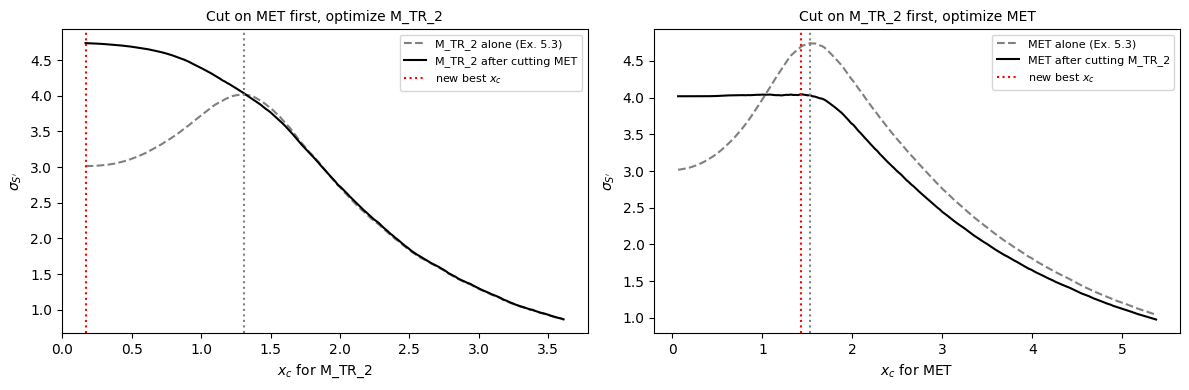

In [36]:
# Step 1: find the most correlated pair among the chosen observables
NS, NB = scenarios[1]                       # change the index to try other scenarios
chosen_vars = [c[0] for c in selections[(NS, NB)]]
corr = np.corrcoef(df[chosen_vars].to_numpy(), rowvar=False)

best_pair, best_r = None, 0
for i in range(len(chosen_vars)):
    for j in range(i + 1, len(chosen_vars)):
        if abs(corr[i, j]) > abs(best_r):
            best_pair, best_r = (chosen_vars[i], chosen_vars[j]), corr[i, j]
print(f"Most correlated pair among chosen observables: {best_pair}, r = {best_r:.2f}")

# Step 2: cut on one, then re-optimize the other
def cut_then_optimize(first, second, NS, NB):
    kind1, mu1 = best_cut[first]
    xc1, _, _, _ = optimize(first, df_sig, df_bkg, NS, NB, len(df_sig), len(df_bkg))
    sig_after = df_sig[passes(df_sig[first].to_numpy(), kind1, mu1, xc1)]
    bkg_after = df_bkg[passes(df_bkg[first].to_numpy(), kind1, mu1, xc1)]

    # "naive" = just reuse the x_c the second variable had on its own in Ex. 5.3
    xc_alone, _, xs_alone, s_alone = optimize(second, df_sig, df_bkg, NS, NB, len(df_sig), len(df_bkg))
    kind2, mu2 = best_cut[second]
    eS_naive = passes(sig_after[second].to_numpy(), kind2, mu2, xc_alone).sum() / len(df_sig)
    eB_naive = passes(bkg_after[second].to_numpy(), kind2, mu2, xc_alone).sum() / len(df_bkg)
    sig_naive = significance(eS_naive, eB_naive, NS, NB)

    # "re-optimized" = find the best x_c again, using only events that survived the first cut
    xc_new, sig_new, xs_new, s_new = optimize(second, sig_after, bkg_after, NS, NB,
                                              len(df_sig), len(df_bkg))
    return dict(first=first, second=second, xc1=xc1, xc_alone=xc_alone, sig_naive=sig_naive,
                xc_new=xc_new, sig_new=sig_new, curves=(xs_alone, s_alone, xs_new, s_new))

A, B = best_pair
res_AB = cut_then_optimize(A, B, NS, NB)    # cut A, optimize B
res_BA = cut_then_optimize(B, A, NS, NB)    # reversed order

rows = []
for r in (res_AB, res_BA):
    rows.append([f"cut {r['first']} (x_c={r['xc1']:.3f}), then {r['second']}",
                 f"{r['xc_alone']:.3f}", f"{r['sig_naive']:.3f}",
                 f"{r['xc_new']:.3f}", f"{r['sig_new']:.3f}"])
display(HTML(tab(rows, headers=["Order", "x_c from 5.3", "σ (5.3 x_c)",
                                "re-optimized x_c", "σ (re-optimized)"], tablefmt="html")))

# Step 3: plot how the significance curve changes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, r in zip(axes, (res_AB, res_BA)):
    xs_alone, s_alone, xs_new, s_new = r["curves"]
    ax.plot(xs_alone, s_alone, color="gray", linestyle="--", label=f"{r['second']} alone (Ex. 5.3)")
    ax.plot(xs_new, s_new, color="black", label=f"{r['second']} after cutting {r['first']}")
    ax.axvline(r["xc_alone"], color="gray", linestyle=":")
    ax.axvline(r["xc_new"], color="red", linestyle=":", label="new best $x_c$")
    ax.set_xlabel(f"$x_c$ for {r['second']}")
    ax.set_ylabel(r"$\sigma_{S'}$")
    ax.set_title(f"Cut on {r['first']} first, optimize {r['second']}", fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Among the observables in Exercise 6.1, MET and M_TR_2 have the strongest correlation (r = 0.72). This means they contain similar information, so applying cuts on both variables can be less effective. For the N_S = 100 and N_B = 1000 scenario, applying the MET cut first (x_c = 1.531) gives a significance of about 4.74. However, adding the M_TR_2 cut from Exercise 5.3 (x_c = 1.31) lowers the significance to 4.03. This is because the M_TR_2 cut removes very little additional background but still removes some signal. When M_TR_2 is re-optimized after the MET cut, the best cut is at the lowest value in the scanned range (0.167), which is basically no cut, so the significance stays at 4.74. Applying the cuts in the opposite order gives a worse result. Cutting on M_TR_2 first gives a significance of about 4.03, and re-optimizing MET only increases it to 4.05. This happens because the M_TR_2 cut has already removed much of the background that the MET cut could have removed, while also losing some signal. Overall, this shows that the order of cuts matters when the variables are correlated. In this case, applying the stronger MET cut first gives the best result, and adding the M_TR_2 cut afterward does not improve the significance.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



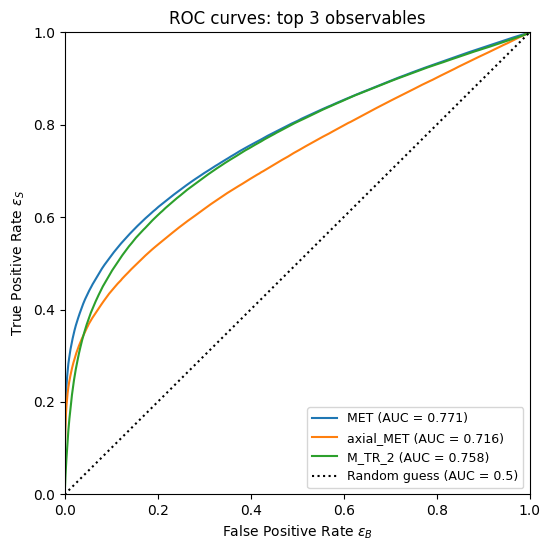

In [37]:
def roc_points(var, sig, bkg, sig_total=None, bkg_total=None, npts=300):
    """Sweep x_c over the full range and return (FPR, TPR) points."""
    sig_total = sig_total or len(df_sig)
    bkg_total = bkg_total or len(df_bkg)
    kind, mu = best_cut[var]
    s = sig[var].to_numpy()
    b = bkg[var].to_numpy()
    allv = np.concatenate([s, b])
    if kind.startswith("|"):
        allv = np.abs(allv - mu)
    # cut values spread evenly through the data, plus one just past each end
    xc = np.quantile(allv, np.linspace(0, 1, npts))
    xc = np.concatenate([[xc[0] - 1e-9], xc, [xc[-1] + 1e-9]])
    tpr = efficiency(s, xc, kind, mu) * len(s) / sig_total
    fpr = efficiency(b, xc, kind, mu) * len(b) / bkg_total
    order = np.argsort(fpr)
    fpr = np.concatenate([[0], fpr[order]])
    tpr = np.concatenate([[0], tpr[order]])
    return fpr, tpr

def auc(fpr, tpr):
    """Area under the curve using the trapezoid rule."""
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)

top3 = [c[0] for c in selections[scenarios[1]]]

fig, ax = plt.subplots(figsize=(6, 6))
for var in top3:
    fpr, tpr = roc_points(var, df_sig, df_bkg)
    ax.plot(fpr, tpr, label=f"{var} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k:", label="Random guess (AUC = 0.5)")
ax.set_xlabel(r"False Positive Rate $\epsilon_B$")
ax.set_ylabel(r"True Positive Rate $\epsilon_S$")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("ROC curves: top 3 observables")
ax.legend(fontsize=9, loc="lower right")
plt.show()

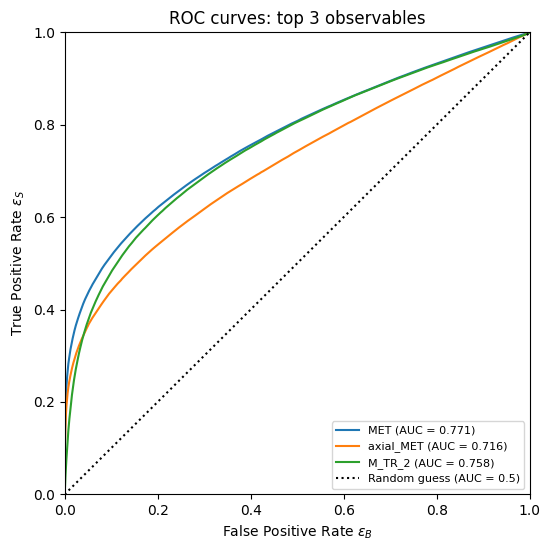

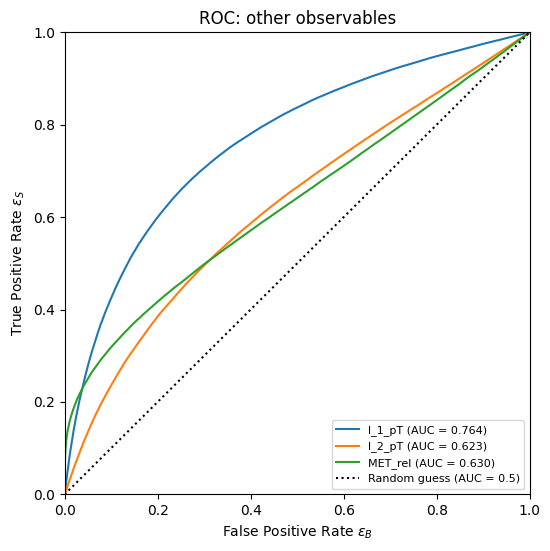

In [38]:
def plot_roc(entries, title="ROC curves", ax=None):
    """
    entries: list of dicts, each with
        "var"   - observable name (required)
        "sig"   - signal events to use (default: all of df_sig)
        "bkg"   - background events to use (default: all of df_bkg)
        "label" - legend text (default: the variable name)
        "mark"  - optional (FPR, TPR) point to highlight, e.g. the chosen cut
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    for e in entries:
        fpr, tpr = roc_points(e["var"], e.get("sig", df_sig), e.get("bkg", df_bkg))
        label = e.get("label", e["var"])
        ax.plot(fpr, tpr, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
        if "mark" in e:
            ax.plot(*e["mark"], "o", color=ax.lines[-1].get_color())
    ax.plot([0, 1], [0, 1], "k:", label="Random guess (AUC = 0.5)")
    ax.set_xlabel(r"False Positive Rate $\epsilon_B$")
    ax.set_ylabel(r"True Positive Rate $\epsilon_S$")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    return ax

# Same figure as 7.1, now in one line:
plot_roc([{"var": v} for v in top3], title="ROC curves: top 3 observables")
plt.show()

# Example with different observables:
plot_roc([{"var": v} for v in ["l_1_pT", "l_2_pT", "MET_rel"]], title="ROC: other observables")
plt.show()

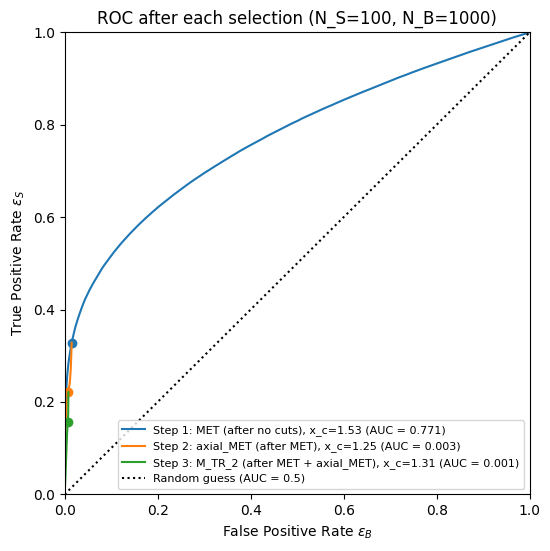

In [39]:
def successive_entries(cuts, reoptimize=False, NS=None, NB=None):
    """Build plot_roc entries: each step's ROC uses only events surviving earlier cuts."""
    sig, bkg = df_sig, df_bkg
    entries = []
    for k, (var, kind, mu, xc) in enumerate(cuts):
        if reoptimize and k > 0:
            xc, _, _, _ = optimize(var, sig, bkg, NS, NB, len(df_sig), len(df_bkg))
        sig_next = sig[passes(sig[var].to_numpy(), kind, mu, xc)]
        bkg_next = bkg[passes(bkg[var].to_numpy(), kind, mu, xc)]
        # dot = where you end up after applying this cut
        mark = (len(bkg_next) / len(df_bkg), len(sig_next) / len(df_sig))
        prev = " + ".join(c[0] for c in cuts[:k]) or "no cuts"
        entries.append({"var": var, "sig": sig, "bkg": bkg, "mark": mark,
                        "label": f"Step {k+1}: {var} (after {prev}), x_c={xc:.2f}"})
        sig, bkg = sig_next, bkg_next
    return entries

NS, NB = scenarios[1]
cuts = selections[(NS, NB)]
plot_roc(successive_entries(cuts), title=f"ROC after each selection (N_S={NS}, N_B={NB})")
plt.show()

MET → axial_MET → M_TR_2                 re-optimized=False:  final ε_S=0.1555  ε_B=0.0068  σ=3.291
M_TR_2 → axial_MET → MET                 re-optimized=False:  final ε_S=0.1555  ε_B=0.0068  σ=3.291
MET → axial_MET → M_TR_2                 re-optimized=True:  final ε_S=0.3275  ε_B=0.0151  σ=4.735
M_TR_2 → axial_MET → MET                 re-optimized=True:  final ε_S=0.2637  ε_B=0.0161  σ=4.044


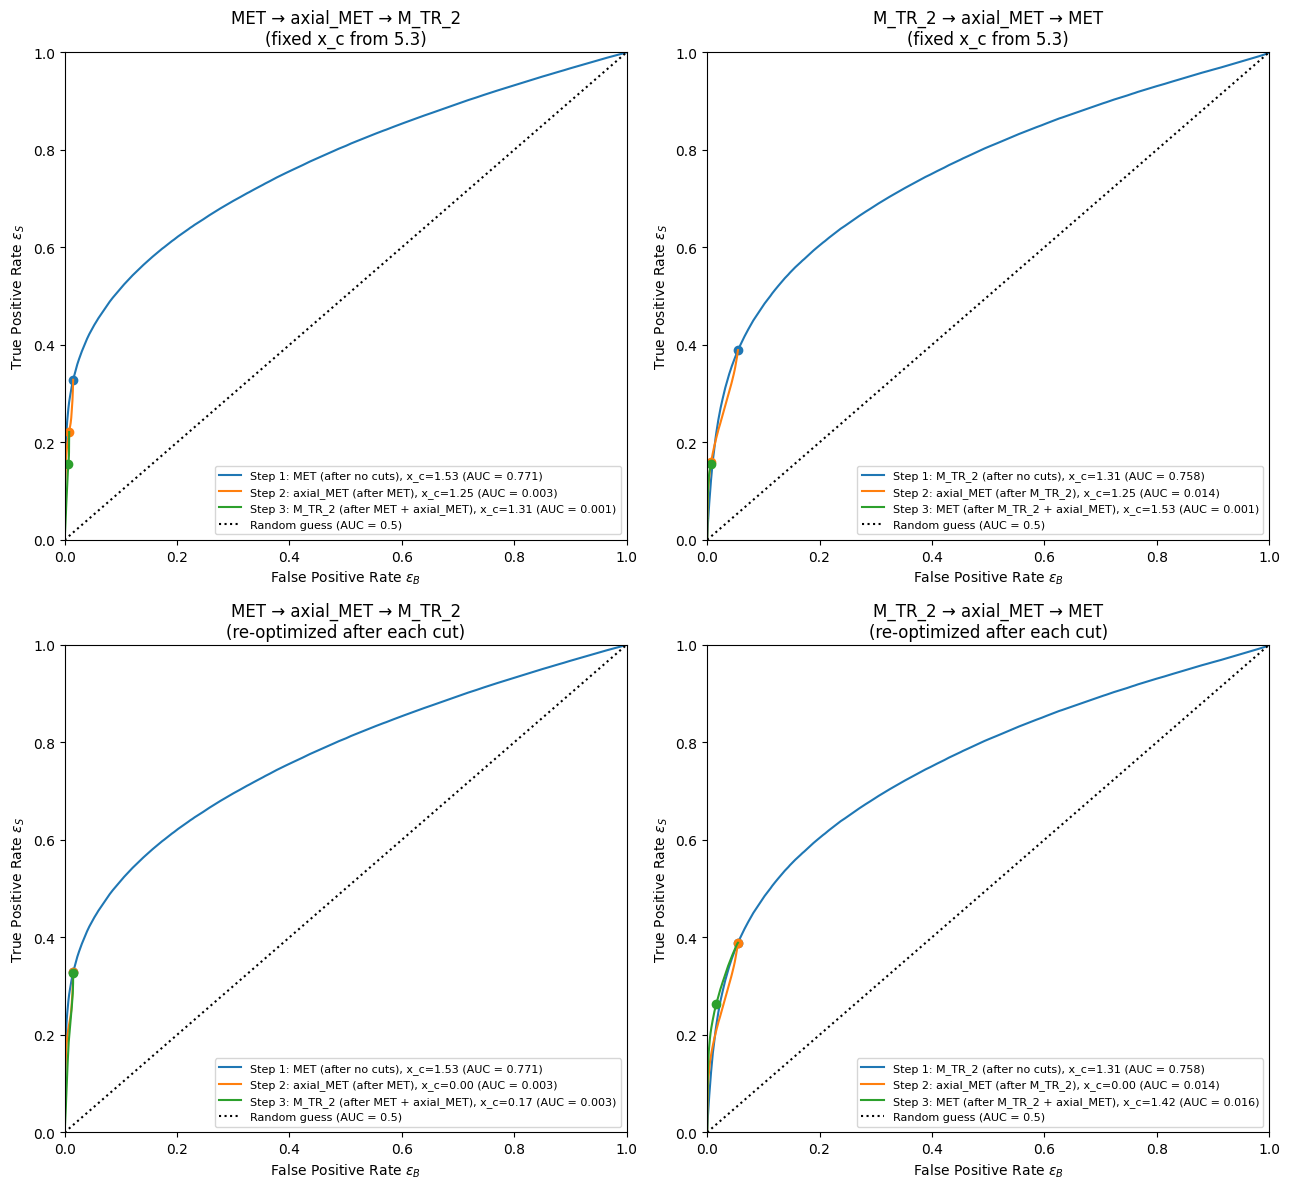

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for row, reopt in enumerate([False, True]):
    for col, order in enumerate([cuts, cuts[::-1]]):      # original order vs. reversed
        ents = successive_entries(order, reoptimize=reopt, NS=NS, NB=NB)
        name = " → ".join(c[0] for c in order)
        plot_roc(ents, ax=axes[row, col],
                 title=f"{name}\n({'re-optimized after each cut' if reopt else 'fixed x_c from 5.3'})")
        eB, eS = ents[-1]["mark"]
        print(f"{name:40s} re-optimized={reopt}:  final ε_S={eS:.4f}  ε_B={eB:.4f}  "
              f"σ={significance(eS, eB, NS, NB):.3f}")
plt.tight_layout()
plt.show()

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [41]:
# category 1 = signal, category 2 = background (as the question defines)
X_sig = df_sig[AllVars].to_numpy()      # shape: (number of signal events, 18)
X_bkg = df_bkg[AllVars].to_numpy()

m1 = X_sig.mean(axis=0)                 # mean of each observable for signal
m2 = X_bkg.mean(axis=0)                 # mean of each observable for background

d = (m2 - m1).reshape(-1, 1)            # column vector
S_B = d @ d.T                           # between-class matrix

# within-class: sum over every event of (x - m)(x - m)^T, done as one matrix multiply
S_W = (X_sig - m1).T @ (X_sig - m1) + (X_bkg - m2).T @ (X_bkg - m2)

print(S_B.shape, S_W.shape)

(18, 18) (18, 18)


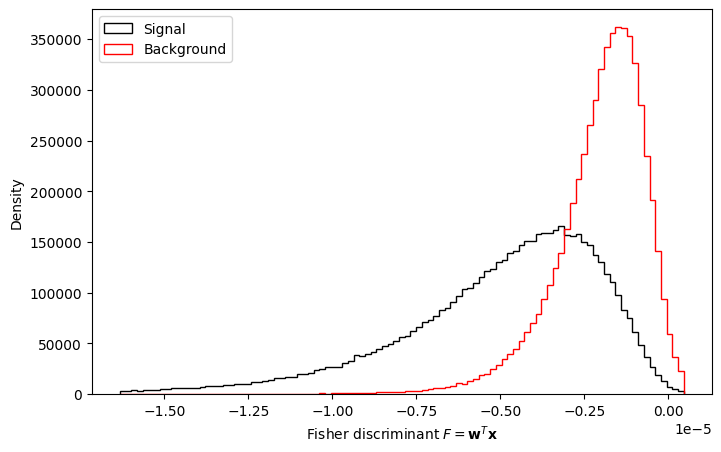

cos_theta_r1    -0.0000
l_1_pT          -0.0000
R                0.0000
S_R              0.0000
M_Delta_R       -0.0000
MET             -0.0000
l_2_pT          -0.0000
MT2              0.0000
M_R              0.0000
axial_MET       -0.0000
M_TR_2          -0.0000
MET_rel         -0.0000
dPhi_r_b         0.0000
l_1_eta         -0.0000
l_2_eta         -0.0000
MET_phi         -0.0000
l_2_phi         -0.0000
l_1_phi         -0.0000


In [42]:
# w = S_W^-1 (m2 - m1); solve() does this without computing the inverse directly (more accurate)
w = np.linalg.solve(S_W, m2 - m1)

F_sig = X_sig @ w        # one F value per signal event
F_bkg = X_bkg @ w        # one F value per background event

lo, hi = np.percentile(np.concatenate([F_sig, F_bkg]), [0.5, 99.5])
bins = np.linspace(lo, hi, 100)

plt.figure(figsize=(8, 5))
plt.hist(F_sig, bins=bins, histtype="step", color="black", density=True, label="Signal")
plt.hist(F_bkg, bins=bins, histtype="step", color="red", density=True, label="Background")
plt.xlabel(r"Fisher discriminant $F = \mathbf{w}^T\mathbf{x}$")
plt.ylabel("Density")
plt.legend()
plt.show()

# see which observables Fisher relies on most
for var, coef in sorted(zip(AllVars, w), key=lambda t: -abs(t[1])):
    print(f"{var:15s} {coef: .4f}")

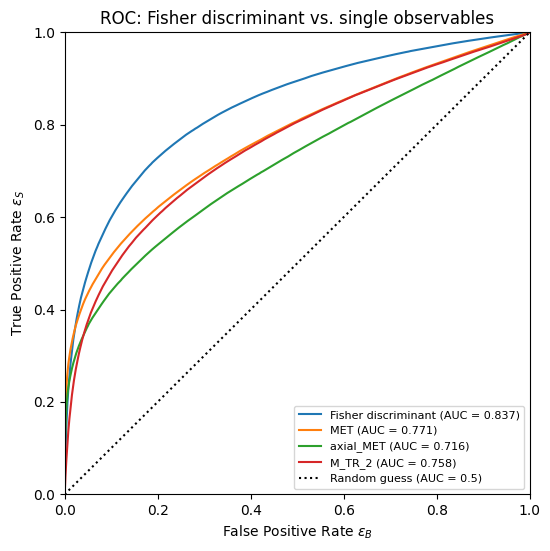

In [43]:
# add F as a new "observable" so plot_roc from Exercise 7 can use it
df_sig = df_sig.assign(Fisher=F_sig)
df_bkg = df_bkg.assign(Fisher=F_bkg)
best_cut["Fisher"] = ("x>xc", 0.0) if F_sig.mean() > F_bkg.mean() else ("x<xc", 0.0)

plot_roc([{"var": "Fisher", "label": "Fisher discriminant"}] + [{"var": v} for v in top3],
         title="ROC: Fisher discriminant vs. single observables")
plt.show()

In [44]:
kind, _ = best_cut["Fisher"]
Fc = np.quantile(np.concatenate([F_sig, F_bkg]), np.linspace(0.001, 0.999, 1000))
eS = efficiency(F_sig, Fc, kind)
eB = efficiency(F_bkg, Fc, kind)

rows = []
for NS, NB in scenarios:
    s = significance(eS, eB, NS, NB)
    i = np.argmax(s)
    sigma_cutflow = cut_flow(selections[(NS, NB)], NS, NB)[-1][-1]   # final σ from Ex. 6
    rows.append([NS, NB, f"{NS/np.sqrt(NS+NB):.3f}", sigma_cutflow,
                 f"{Fc[i]:.4g}", f"{eS[i]:.4f}", f"{eB[i]:.4f}", f"{s[i]:.3f}"])

display(HTML(tab(rows, headers=["N_S", "N_B", "σ no cut", "σ cut flow (Ex. 6)",
                                "best F_c", "ε_S", "ε_B", "max σ (Fisher)"], tablefmt="html")))

N_S,N_B,σ no cut,σ cut flow (Ex. 6),best F_c,ε_S,ε_B,max σ (Fisher)
10,100,0.953,1.041,-4.495e-06,0.492,0.0539,1.532
100,1000,3.015,3.291,-4.495e-06,0.492,0.0539,4.846
1000,10000,9.535,10.408,-4.495e-06,0.492,0.0539,15.324
10000,100000,30.151,32.912,-4.495e-06,0.492,0.0539,48.457
